# Airline Delays and Passenger Satisfaction

### Micro Project #1-4


Darren Levreault  
ANA500

## Problem Statement

This project examines whether flight distance is associated with arrival delay
after accounting for departure delay, and whether longer arrival delays are
associated with lower passenger satisfaction.

## Hypothesis

**H₁a - Delay:** After accounting for departure delay, flight distance is
associated with arrival delay.

**H₁b - Satisfaction:** Records with longer arrival delays have a lower
percentage of satisfied passengers.

## Step 1: Acquire

The airline dataset provided is a CSV file. I will load it into a Pandas DataFrame and check its size and first few records before preparing the data.

In [1]:
import tensorflow as tf

In [2]:
# Import libraries
import pandas as pd
import numpy as np
# Visual Libraries
import matplotlib.pyplot as plt
import seaborn as sns
# Modeling Libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.base import clone


# Read the CSV file.
airline = pd.read_csv("airline.csv")

# Check how many rows and columns
print("Rows and columns:", airline.shape)

# Display 
airline.head()

Rows and columns: (129880, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


## Step 2: Prepare
I will inspect the variables, check data quality, and prepare the records needed to study arrival delay. Each cleaning decision is documented below.

In [3]:
# Show each column's name, data type, and number of non-missing values.
airline.info()

# Count missing values 
missing_values = airline.isna().sum().sort_values(ascending=False)
print("\nMissing values by column:")
print(missing_values)

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         129880 non-null  int64  
 1   id                                 129880 non-null  int64  
 2   Gender                             129880 non-null  str    
 3   Customer Type                      129880 non-null  str    
 4   Age                                129880 non-null  int64  
 5   Type of Travel                     129880 non-null  str    
 6   Class                              129880 non-null  str    
 7   Flight Distance                    129880 non-null  int64  
 8   Inflight wifi service              129880 non-null  int64  
 9   Departure/Arrival time convenient  129880 non-null  int64  
 10  Ease of Online booking             129880 non-null  int64  
 11  Gate location                      129880 non-null

The dataset contains 129,880 records and 25 columns. Arrival delay is the only column with missing values (393 records). Before cleaning, I will check for duplicate records and examine the ranges of the variables central to the project.

In [4]:
# Check Duplicate's
print("Duplicate rows:", airline.duplicated().sum())


Duplicate rows: 0


In [5]:
# Summarize numeric column's distribution.
numeric_summary = airline.select_dtypes(include=np.number).describe().T

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,129880.0,44158.700000,31207.377062,0.0,16234.75,38963.5,71433.25,103903.0
id,129880.0,64940.500000,37493.270818,1.0,32470.75,64940.5,97410.25,129880.0
Age,129880.0,39.427957,15.119360,7.0,27.00,40.0,51.00,85.0
Flight Distance,129880.0,1190.316392,997.452477,31.0,414.00,844.0,1744.00,4983.0
Inflight wifi service,129880.0,2.728696,1.329340,0.0,2.00,3.0,4.00,5.0
Departure/Arrival time convenient,129880.0,3.057599,1.526741,0.0,2.00,3.0,4.00,5.0
Ease of Online booking,129880.0,2.756876,1.401740,0.0,2.00,3.0,4.00,5.0
Gate location,129880.0,2.976925,1.278520,0.0,2.00,3.0,4.00,5.0
Food and drink,129880.0,3.204774,1.329933,0.0,2.00,3.0,4.00,5.0
Online boarding,129880.0,3.252633,1.350719,0.0,2.00,3.0,4.00,5.0


Most flights have a recorded delay of zero minutes, while a smaller number have very long delays. I will examine these extreme values before deciding whether to change them. The service ratings are coded as numbers, but they represent rating levels. 

In [6]:
# Checking text variables and show the categories in each one.

categorical_columns = airline.select_dtypes(
    include=["object", "string"]
).columns

# Show the number of records in each category, including missing values.
for column in categorical_columns:
    print(f"\n{column}")
    print(airline[column].value_counts(dropna=False))


Gender
Gender
Female    65899
Male      63981
Name: count, dtype: int64

Customer Type
Customer Type
Loyal Customer       106100
disloyal Customer     23780
Name: count, dtype: int64

Type of Travel
Type of Travel
Business travel    89693
Personal Travel    40187
Name: count, dtype: int64

Class
Class
Business    62160
Eco         58309
Eco Plus     9411
Name: count, dtype: int64

satisfaction
satisfaction
neutral or dissatisfied    73452
satisfied                  56428
Name: count, dtype: int64


The five text columns contain consistent categories. No category labels need cleaning at this stage. 

In [7]:
# Create a cleaned DF by removing uneeded numeric variables, no other changes to data made here.
airline_df = airline.drop(columns=["Unnamed: 0", "id"]).copy()

# Remove rows where the arrival delay is unknown/missing. ~0.3% of Data affected. Removing > imputation in this case.
airline_df = airline_df.dropna(subset=["Arrival Delay in Minutes"])

print("Cleaned dataset shape:", airline_df.shape)

Cleaned dataset shape: (129487, 23)


In [8]:
# Check for missing values in the cleaned dataset.
print("Total missing values:", airline_df.isna().sum().sum())

# Check duplicates 
print("Duplicate data rows:", airline_df.duplicated().sum())

Total missing values: 0
Duplicate data rows: 0


After removing records without an arrival delay and dropping the identifier columns, the prepared dataset contains 129,487 rows and 23 columns. It has no remaining missing values or duplicate rows.

In [9]:
# Convert the numeric columns to a NumPy array for a data validity check.
numeric_values = airline_df.select_dtypes(include=np.number).to_numpy()

# Check for infinite or non-numeric values in the numeric columns.
print("All numeric values are finite:", np.isfinite(numeric_values).all())

#Check for negitives in variables where should not exist.
print("Negative departure delays:",
      (airline_df["Departure Delay in Minutes"] < 0).sum())
print("Negative arrival delays:",
      (airline_df["Arrival Delay in Minutes"] < 0).sum())
print("Zero or negative flight distances:",
      (airline_df["Flight Distance"] <= 0).sum())

All numeric values are finite: True
Negative departure delays: 0
Negative arrival delays: 0
Zero or negative flight distances: 0


In [10]:
# Review 10 records with the longest recorded arrival delays.
# Compare arrival delay with departure delay and flight distance, are they consistant values? Validity check.

longest_delays = airline_df.nlargest(10, "Arrival Delay in Minutes")[
    ["Departure Delay in Minutes", "Arrival Delay in Minutes", "Flight Distance"]
]

display(longest_delays)

,Departure Delay in Minutes,Arrival Delay in Minutes,Flight Distance
83741,1592,1584.0,1120
6744,1305,1280.0,2916
121333,1128,1115.0,1144
61310,1017,1011.0,1959
72206,978,970.0,1598
61287,930,952.0,2418
105559,951,940.0,1696
61528,921,924.0,577
80182,933,920.0,2187
27732,859,860.0,1746


The longest arrival delays are accompanied by similarly long departure delays. Although these values are unusual, this check does not show an obvious data error. I retained them so that the prepared data still represents flights with severe/outlying delays. 

In [11]:
# Contains columns needed for both hypotheses.
delay_df = airline_df[
    [
        "Departure Delay in Minutes",
        "Flight Distance",
        "Arrival Delay in Minutes",
        "satisfaction",
        "Class",
        "Type of Travel",
        "Customer Type"
    ]
].copy()

# Confirm size & check columns.
print("Focused dataset shape:", delay_df.shape)
display(delay_df.head())

Focused dataset shape: (129487, 7)


,Departure Delay in Minutes,Flight Distance,Arrival Delay in Minutes,satisfaction,Class,Type of Travel,Customer Type
0,25,460,18.0,neutral or dissatisfied,Eco Plus,Personal Travel,Loyal Customer
1,1,235,6.0,neutral or dissatisfied,Business,Business travel,disloyal Customer
2,0,1142,0.0,satisfied,Business,Business travel,Loyal Customer
3,11,562,9.0,neutral or dissatisfied,Business,Business travel,Loyal Customer
4,0,214,0.0,satisfied,Business,Business travel,Loyal Customer


### Preparation summary

I loaded 129,880 records from the provided airline dataset. I examined all numeric and categorical columns, checked missing values and duplicates, and reviewed the longest delays. I removed the two identifier columns and 393 records with no known arrival delay. The resulting `airline_df` has 129,487 records and 23 columns, with no missing values or duplicate rows. I retained the unusually long delays because the records did not show an obvious error.

I created `delay_df` with seven columns: departure delay, flight distance, arrival delay, satisfaction, class, type of travel, and customer type. The three numeric columns support the flight distance and arrival delay question (H₁a). Arrival delay and satisfaction support the satisfaction question (H₁b). The travel characteristics will help compare patterns across passenger groups.

## Step 3: Analyze

I will first use visualizations to explore the two hypotheses. The grouped charts show patterns, but they do not account for each record's exact departure-delay value.  

> For H₁a, I will compare regression models that predict arrival delay in minutes. The first will use departure delay alone, and the second will add flight distance. Comparing their results on the same test set will show whether flight distance adds useful predictive information after accounting for departure delay as a continuous variable.

>For H₁b, I will examine whether arrival delay is associated with passenger satisfaction when passenger characteristics and selected service ratings are also considered.


### Exploratory visual analysis

### Visual #1

In [12]:
# Check arrival-delay percentiles to adjust visual window below. 
# Full range plot can be improved for data vis.

arrival_delay = delay_df["Arrival Delay in Minutes"]

delay_percentiles = arrival_delay.quantile([0.50, 0.75, 0.90, 0.95, 0.975, 0.99])

display(delay_percentiles)

0.500      0.0
0.750     13.0
0.900     44.0
0.950     78.0
0.975    120.0
0.990    182.0
Name: Arrival Delay in Minutes, dtype: float64

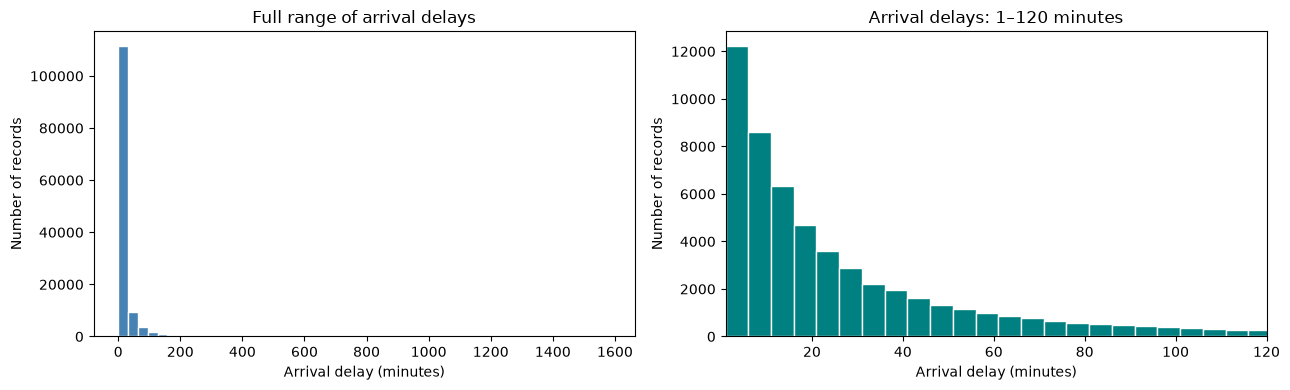

In [13]:
# Create two charts side by side: the full range and a closer view.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Show all arrival-delay values, including unusually long delays.
axes[0].hist(arrival_delay, bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Full range of arrival delays")
axes[0].set_xlabel("Arrival delay (minutes)")
axes[0].set_ylabel("Number of records")
# Select positive arrival delays up to 120 minutes for the close-up.
positive_delays = arrival_delay[(arrival_delay > 0) & (arrival_delay <= 120)]

axes[1].hist(
    positive_delays,
    bins=range(1, 127, 5),
    color="teal",
    edgecolor="white"
)
axes[1].set_xlim(1, 120)
axes[1].set_title("Arrival delays: 1–120 minutes")
axes[1].set_xlabel("Arrival delay (minutes)")
axes[1].set_ylabel("Number of records")

plt.tight_layout()

#export plots
plt.savefig("arrival_delay_distribution.png", dpi=200, bbox_inches="tight")

plt.show()

In [14]:
# Count records in three arrival-delay groups.
zero_count = (arrival_delay == 0).sum()
one_to_120_count = arrival_delay.between(1, 120).sum()
over_120_count = (arrival_delay > 120).sum()

# Put the counts and percentages in a table.
delay_counts = pd.DataFrame({
    "Arrival delay": ["0 minutes", "1–120 minutes", "Over 120 minutes"],
    "Records": [zero_count, one_to_120_count, over_120_count]
})
delay_counts["Percent of records"] = (
    delay_counts["Records"] / len(arrival_delay) * 100
).round(1)

display(delay_counts)

,Arrival delay,Records,Percent of records
0,0 minutes,72753,56.2
1,1–120 minutes,53542,41.3
2,Over 120 minutes,3192,2.5


Arrival delays are strongly right-skewed. Of the 129,487 records, 56.2% have no arrival delay, 41.3% have a delay of 1–120 minutes, and 2.5% exceed 120 minutes. The full-range chart retains the unusually long delays; the close-up excludes zero delays so the pattern among shorter delays is easier to see. Within that close-up, the number of records generally decreases as delay length increases.

### Visual #2

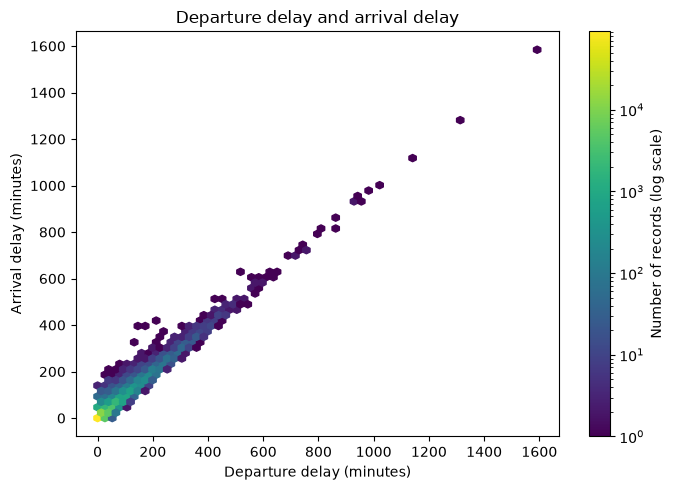

In [15]:
# Use a hexbin chart to show where departure and arrival delays 
# are concentrated across all prepared records.
fig, ax = plt.subplots(figsize=(7, 5))

hexes = ax.hexbin(
    delay_df["Departure Delay in Minutes"],
    delay_df["Arrival Delay in Minutes"],
    gridsize=60,
    mincnt=1,
    bins="log",
    cmap="viridis"
)

# The color scale shows record density. A log scale helps distinguish
# less common areas from the heavily concentrated short delays.
fig.colorbar(hexes, ax=ax, label="Number of records (log scale)")
ax.set_title("Departure delay and arrival delay")
ax.set_xlabel("Departure delay (minutes)")
ax.set_ylabel("Arrival delay (minutes)")

plt.tight_layout()

#Export
fig.savefig("departure_arrival_hexbin.png", dpi=300, bbox_inches="tight")

plt.show()

*Interpretation*: Departure and arrival delays have a strong positive association in these records. Most observations are concentrated near shorter delays, while very long delays are uncommon. This relationship provides a baseline for H₁a; the chart alone does not tell us whether flight distance adds information after accounting for departure delay.

### Visual #3

In [16]:
# Make a separate DataFrame for the distance comparison.
# no change to delay_df.
distance_analysis = delay_df[
    ["Departure Delay in Minutes", "Flight Distance", "Arrival Delay in Minutes"]
].copy()

# Divide flight distances into four groups with approximately equal
# numbers of records. Q1 contains the shortest distances; Q4 the longest.
distance_analysis["Distance group"] = pd.qcut(
    distance_analysis["Flight Distance"],
    q=4,
    labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"]
)

# Group departure delays so distances can be compared among records
# that left with roughly similar delays.
distance_analysis["Departure delay group"] = pd.cut(
    distance_analysis["Departure Delay in Minutes"],
    bins=[-0.5, 0.5, 15.5, 30.5, 60.5, 120.5, float("inf")],
    labels=["0", "1–15", "16–30", "31–60", "61–120", "Over 120"]
)

# Check the number of records in each combination before plotting.
group_counts = pd.crosstab(
    distance_analysis["Departure delay group"],
    distance_analysis["Distance group"]
)
display(group_counts)

Distance group,Q1 shortest,Q2,Q3,Q4 longest
Departure delay group,,,,
0,19602,17922,17650,18035
1–15,6221,6745,7495,7249
16–30,2393,2735,2869,2601
31–60,2256,2362,2323,2140
61–120,1454,1619,1436,1324
Over 120,677,827,805,747


Distance group,Q1 shortest,Q2,Q3,Q4 longest
Departure delay group,,,,
0,0.0,0.0,0.0,0.0
1–15,3.0,2.0,0.0,1.0
16–30,18.0,17.0,15.0,16.0
31–60,40.0,38.0,36.0,38.0
61–120,81.0,79.0,80.0,79.0
Over 120,169.0,166.0,167.0,173.0


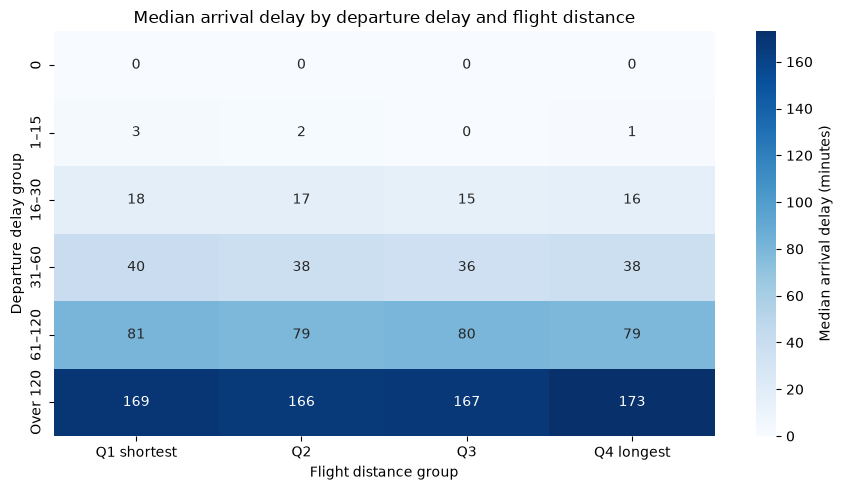

In [17]:
# Calculate the median arrival delay for each combination of
# departure-delay group and flight-distance group.
median_arrival = distance_analysis.pivot_table(
    index="Departure delay group",
    columns="Distance group",
    values="Arrival Delay in Minutes",
    aggfunc="median",
    observed=True
)

# Display the exact values as a table.
display(median_arrival)

# Use a heatmap to make comparisons within each departure-delay row.
plt.figure(figsize=(9, 5))
sns.heatmap(
    median_arrival,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    cbar_kws={"label": "Median arrival delay (minutes)"}
)
plt.title("Median arrival delay by departure delay and flight distance")
plt.xlabel("Flight distance group")
plt.ylabel("Departure delay group")
plt.tight_layout()
plt.savefig("distance_delay_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

Median arrival delay increased substantially across departure-delay groups. Within most departure-delay groups, differences across flight-distance quartiles were small and did not follow a consistent pattern. This grouped comparison does not provide clear descriptive support for a distance effect; a regression model can assess flight distance while accounting for departure delay more precisely.

# Visual #4

In [18]:
# Make a separate dataset for the satisfaction question.
satisfaction_analysis = delay_df[
    ["Arrival Delay in Minutes", "satisfaction"]
].copy()

# Put arrival delays into ranges, keeping records with zero delay separate.
satisfaction_analysis["Arrival delay group"] = pd.cut(
    satisfaction_analysis["Arrival Delay in Minutes"],
    bins=[-0.5, 0.5, 15.5, 30.5, 60.5, 120.5, float("inf")],
    labels=["0", "1–15", "16–30", "31–60", "61–120", "Over 120"]
)

# True represents a satisfied passenger; its group mean is the satisfied share.
satisfaction_analysis["Satisfied"] = (
    satisfaction_analysis["satisfaction"] == "satisfied"
)

# Show both the number of records and the satisfaction percentage.
satisfaction_summary = satisfaction_analysis.groupby(
    "Arrival delay group", observed=True
).agg(
    records=("Satisfied", "size"),
    satisfaction_rate=("Satisfied", "mean")
)

satisfaction_summary["satisfaction_rate"] *= 100
display(satisfaction_summary.round(1))

,records,satisfaction_rate
Arrival delay group,,
0,72753,47.4
1–15,27176,41.2
16–30,11183,35.7
31–60,9287,36.1
61–120,5896,35.3
Over 120,3192,36.1


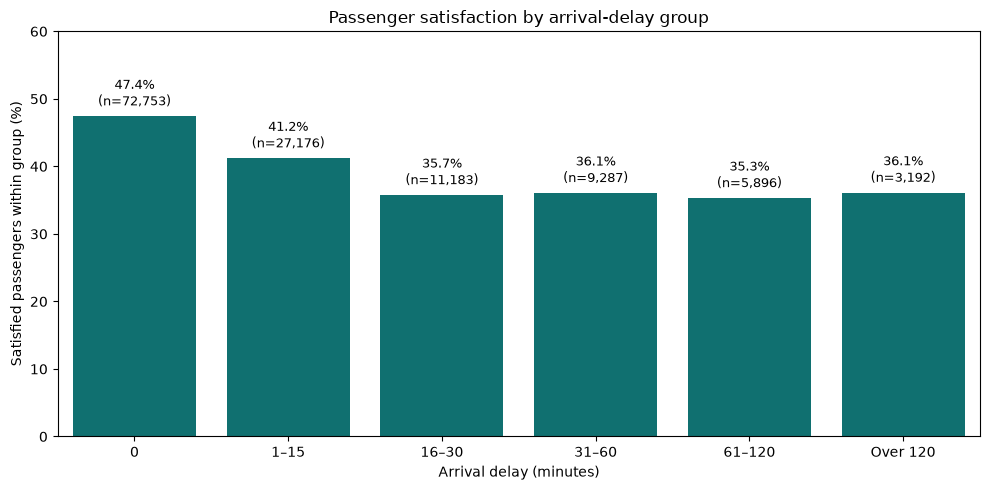

In [19]:
# Turn the summary table into columns that Seaborn can use.
plot_data = satisfaction_summary.reset_index()

# Each bar shows the percentage satisfied within that arrival-delay group.
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=plot_data,
    x="Arrival delay group",
    y="satisfaction_rate",
    color="teal",
    ax=ax
)

# Label each bar with its percentage and number of records.
for bar, rate, count in zip(
    ax.patches,
    plot_data["satisfaction_rate"],
    plot_data["records"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.1f}%\n(n={count:,})",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(0, 60)
ax.set_title("Passenger satisfaction by arrival-delay group")
ax.set_xlabel("Arrival delay (minutes)")
ax.set_ylabel("Satisfied passengers within group (%)")

plt.tight_layout()
plt.savefig("satisfaction_by_arrival_delay.png", dpi=200, bbox_inches="tight")
plt.show()

Satisfaction was highest among records with no arrival delay (47.4%) and lower among records with delays of 16 minutes or more (approximately 35–36%). The rate did not decline consistently across the longer delay groups. These descriptive results partly support H₁b, but they do not establish that delays caused the difference in satisfaction.

### Visual #5

In [20]:
#check whether that pattern appears within both travel types.
# Keep travel type alongside each record's delay group and satisfaction status.
travel_satisfaction = delay_df[
    ["Type of Travel", "Arrival Delay in Minutes", "satisfaction"]
].copy()

travel_satisfaction["Arrival delay group"] = satisfaction_analysis[
    "Arrival delay group"
]
travel_satisfaction["Satisfied"] = (
    travel_satisfaction["satisfaction"] == "satisfied"
)

# Calculate the satisfaction percentage separately for each travel type
# and arrival-delay group. Keep counts to assess group sizes.
travel_summary = travel_satisfaction.groupby(
    ["Type of Travel", "Arrival delay group"],
    observed=True
).agg(
    records=("Satisfied", "size"),
    satisfaction_rate=("Satisfied", "mean")
)

travel_summary["satisfaction_rate"] *= 100
display(travel_summary.round(1))

records  satisfaction_rate
Type of Travel  Arrival delay group                            
Business travel 0                      50039               63.0
                1–15                   18849               55.7
                16–30                   7760               49.7
                31–60                   6502               49.8
                61–120                  4050               49.4
                Over 120                2245               49.1
Personal Travel 0                      22714               13.1
                1–15                    8327                8.3
                16–30                   3423                4.0
                31–60                   2785                4.0
                61–120                  1846                4.4
                Over 120                 947                5.2

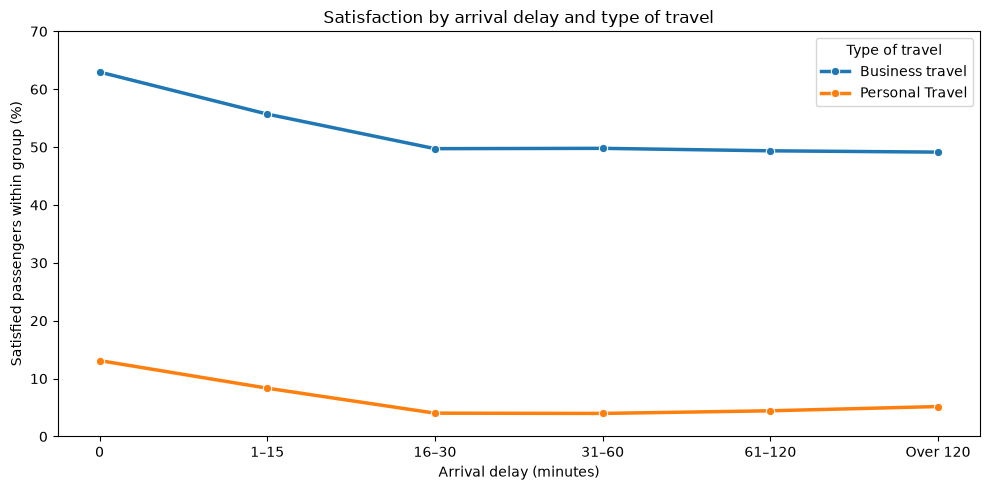

In [21]:
# Convert the grouped summary into columns for plotting.
travel_plot = travel_summary.reset_index()

# Compare satisfaction percentages across ordered delay groups
# for business and personal travel.
fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=travel_plot,
    x="Arrival delay group",
    y="satisfaction_rate",
    hue="Type of Travel",
    marker="o",
    linewidth=2.5,
    sort=False,
    ax=ax
)

ax.set_title("Satisfaction by arrival delay and type of travel")
ax.set_xlabel("Arrival delay (minutes)")
ax.set_ylabel("Satisfied passengers within group (%)")
ax.set_ylim(0, 70)
ax.legend(title="Type of travel")

plt.tight_layout()
plt.savefig("satisfaction_delay_by_travel_type.png", dpi=200, bbox_inches="tight")
plt.show()

Within both travel types, the percentage of satisfied passengers decreased from the no-delay group to the 16–30 minute arrival-delay group. For business travel, it fell from 63.0% to 49.7%; for personal travel, it fell from 13.1% to 4.0%. Satisfaction then remained relatively stable across longer delay groups. This supports the early decline proposed in H₁b, but not a continuous decline as delays grow. These comparisons are descriptive and do not establish causation.

### Visual #6 

In [22]:
# Compare satisfaction across travel classes and arrival-delay groups.
class_analysis = delay_df[
    ["Class", "Arrival Delay in Minutes", "satisfaction"]
].copy()

# Reuse the same delay groups so the comparisons stay consistent.
class_analysis["Arrival delay group"] = satisfaction_analysis[
    "Arrival delay group"
]

# A True value means the record is labeled "satisfied."
class_analysis["Satisfied"] = (
    class_analysis["satisfaction"] == "satisfied"
)

# Calculate the number of records and percent satisfied in each group.
class_summary = class_analysis.groupby(
    ["Class", "Arrival delay group"],
    observed=True
).agg(
    records=("Satisfied", "size"),
    satisfaction_rate=("Satisfied", "mean")
)

class_summary["satisfaction_rate"] *= 100
display(class_summary.round(1))

records  satisfaction_rate
Class    Arrival delay group                            
Business 0                      35296               73.1
         1–15                   13054               67.3
         16–30                   5223               62.0
         31–60                   4325               62.6
         61–120                  2632               62.0
         Over 120                1460               61.1
Eco      0                      32376               22.2
         1–15                   12116               16.2
         16–30                   5109               12.1
         31–60                   4222               12.9
         61–120                  2806               13.0
         Over 120                1488               14.5
Eco Plus 0                       5081               29.4
         1–15                    2006               22.3
         16–30                    851               16.5
         31–60                    740               13.4
         61–120                   458               18.3
         Over 120                 244               18.0

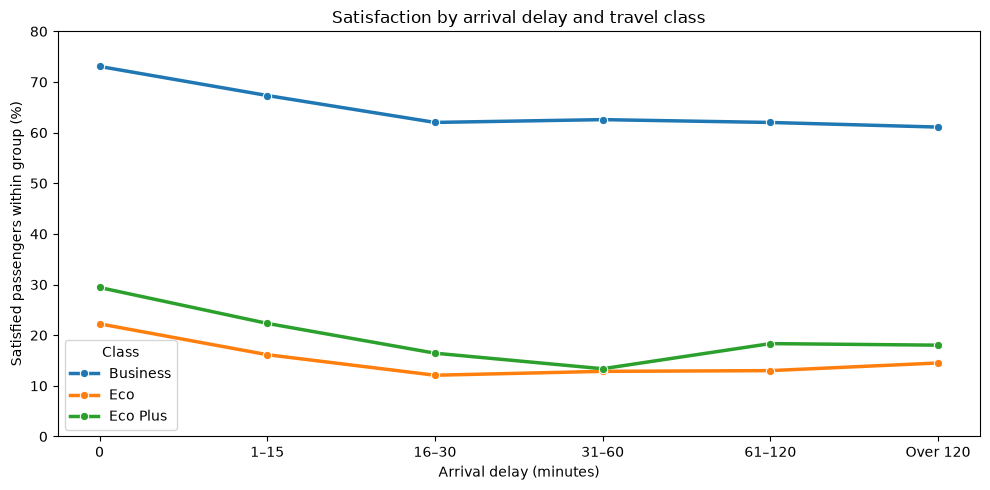

In [23]:
# Convert the class summary into columns for Seaborn.
class_plot = class_summary.reset_index()

# Plot the satisfaction percentage within each class and delay group.
fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=class_plot,
    x="Arrival delay group",
    y="satisfaction_rate",
    hue="Class",
    marker="o",
    linewidth=2.5,
    sort=False,
    ax=ax
)

ax.set_title("Satisfaction by arrival delay and travel class")
ax.set_xlabel("Arrival delay (minutes)")
ax.set_ylabel("Satisfied passengers within group (%)")
ax.set_ylim(0, 80)
ax.legend(title="Class")

plt.tight_layout()
plt.savefig("satisfaction_delay_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

Satisfaction varied substantially by travel class. In each class, the satisfied percentage was lower for 16–30 minute arrival delays than for no delay. Rates did not continue to decline consistently in the longer delay groups. The smaller Eco Plus groups make its later fluctuations less certain.

### Visual #7

,Departure delay,Flight distance,Arrival delay
Departure delay,1.000,0.025,0.740
Flight distance,0.025,1.000,-0.002
Arrival delay,0.740,-0.002,1.000


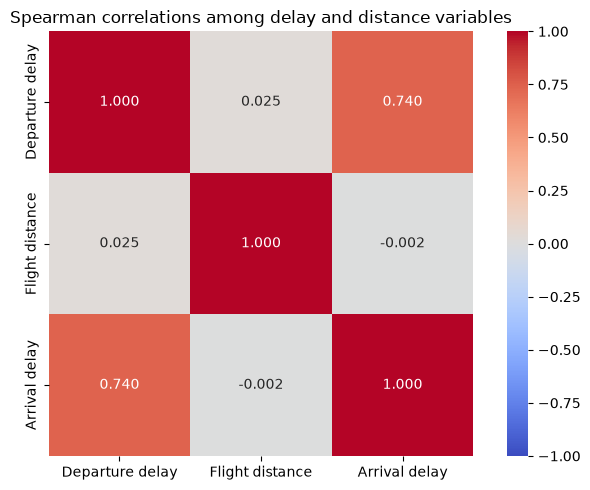

In [24]:
# Select the three numeric variables in the arrival-delay question.
# Shorter display names make the heatmap easier to read.
correlation_data = delay_df[
    [
        "Departure Delay in Minutes",
        "Flight Distance",
        "Arrival Delay in Minutes"
    ]
].rename(columns={
    "Departure Delay in Minutes": "Departure delay",
    "Flight Distance": "Flight distance",
    "Arrival Delay in Minutes": "Arrival delay"
})

# Spearman correlation compares ranked values. It is useful here because
# delays include many zeros and some unusually large values.
spearman_corr = correlation_data.corr(method="spearman")
display(spearman_corr.round(3))

# Plot the pairwise correlations on a common scale from -1 to +1.
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax
)

ax.set_title("Spearman correlations among delay and distance variables")
plt.tight_layout()
plt.savefig("delay_distance_correlation.png", dpi=200, bbox_inches="tight")
plt.show()

Departure and arrival delays had a strong positive Spearman correlation (ρ = 0.740). Flight distance had almost no pairwise correlation with arrival delay (ρ = −0.002). Together with the grouped heatmap, this provides little descriptive evidence of a distance pattern. Pairwise correlation does not account for departure delay.


### Visual #8

,count,median
Distance group,,
Q1 shortest,4649,-4.0
Q2,5097,-5.0
Q3,5192,-7.0
Q4 longest,4741,-6.0


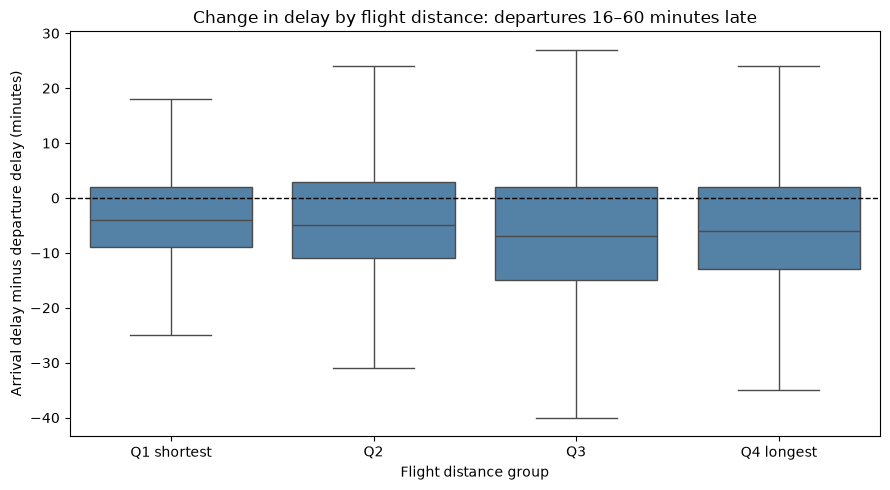

In [25]:
# Compare the change in delay from departure to arrival.
recovery_analysis = distance_analysis.copy()
recovery_analysis["Net delay change"] = (
    recovery_analysis["Arrival Delay in Minutes"]
    - recovery_analysis["Departure Delay in Minutes"]
)

# Focus on records with a departure delay of 16–60 minutes.
# This avoids letting the large zero-delay group dominate the comparison.
recovery_subset = recovery_analysis[
    recovery_analysis["Departure Delay in Minutes"].between(16, 60)
].copy()

# Check the number of records and median change in each distance group.
recovery_summary = recovery_subset.groupby(
    "Distance group", observed=True
)["Net delay change"].agg(["count", "median"])

display(recovery_summary)

# Show the spread of net delay changes by distance group.
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=recovery_subset,
    x="Distance group",
    y="Net delay change",
    showfliers=False,
    color="steelblue",
    ax=ax
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Change in delay by flight distance: departures 16–60 minutes late")
ax.set_xlabel("Flight distance group")
ax.set_ylabel("Arrival delay minus departure delay (minutes)")

plt.tight_layout()
plt.savefig("net_delay_change_by_distance.png", dpi=200, bbox_inches="tight")
plt.show()

In [26]:
# Calculate median net delay change for every departure-delay range
# and flight-distance group. Negative values mean the arrival delay
# was smaller than the departure delay.
net_change_by_group = recovery_analysis.pivot_table(
    index="Departure delay group",
    columns="Distance group",
    values="Net delay change",
    aggfunc="median",
    observed=True
)

display(net_change_by_group)

Distance group,Q1 shortest,Q2,Q3,Q4 longest
Departure delay group,,,,
0,0.0,0.0,0.0,0.0
1–15,-2.0,-2.0,-2.0,-2.0
16–30,-4.0,-5.0,-7.0,-6.0
31–60,-4.0,-5.0,-7.0,-5.0
61–120,-3.0,-5.0,-6.0,-5.0
Over 120,-2.0,-3.0,-6.0,-5.0


Among records departing 16–60 minutes late, median arrival delay was 4–7 minutes lower than departure delay, with the largest median reduction in Q3. A check across all departure-delay groups found the same Q3 pattern in groups departing at least 16 minutes late. This is exploratory evidence that net delay change varies by distance group, though the relationship is not steadily increasing and the grouped comparisons do not account for exact departure delay.

## ANALYZE: Part #2 (MicroProject-3)

### Regression modeling for H₁a: Does flight distance add predictive value?

The visualizations compared groups of records. Here I will use each record's exact departure delay to test whether adding flight distance improves predictions of arrival delay. I will compare the models using the same training and test split.

In [27]:
# Prepare the arrival-delay modeling data.
# The outcome (y) is arrival delay in minutes.
# Both predictors remain continuous; we do not put them into groups.
X_delay = delay_df[
    ["Departure Delay in Minutes", "Flight Distance"]
]
y_delay = delay_df["Arrival Delay in Minutes"]

# Reserve 20% of the records to test the models on data they did not train on.
# random_state makes the split reproducible when the notebook is rerun.
X_train, X_test, y_train, y_test = train_test_split(
    X_delay,
    y_delay,
    test_size=0.20,
    random_state=1031
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))

Training records: 103589
Test records: 25898


#### Model 1 — Linear regression: departure delay only

In [28]:
# Baseline model: predict arrival delay using departure delay alone.
# Double brackets keep the predictor as a one-column DataFrame.
X_train_departure = X_train[["Departure Delay in Minutes"]]
X_test_departure = X_test[["Departure Delay in Minutes"]]

# Fit the model using only the training records.
departure_model = LinearRegression()
departure_model.fit(X_train_departure, y_train)

# Predict arrival delays for the held-out test records.
departure_predictions = departure_model.predict(X_test_departure)

print("Baseline model fitted.")
print("Test predictions:", len(departure_predictions))

Baseline model fitted.
Test predictions: 25898


In [29]:
# Evaluate predictions against the actual arrival delays in the test set.
# MAE is the average absolute error, measured in minutes.
# RMSE is also in minutes but gives more weight to large errors.
# R² measures how much variation the model explains on the test set.
baseline_results = {
    "Model": "Departure delay only",
    "MAE (minutes)": mean_absolute_error(y_test, departure_predictions),
    "RMSE (minutes)": np.sqrt(
        mean_squared_error(y_test, departure_predictions)
    ),
    "R²": r2_score(y_test, departure_predictions)
}

display(pd.DataFrame([baseline_results]).round(3))

,Model,MAE (minutes),RMSE (minutes),R²
0,Departure delay only,5.289,10.025,0.933


#### Model 2 — Linear regression: departure delay + flight distance

In [30]:
# Expanded model: use both departure delay and flight distance.
# X_train and X_test contain the same records used for the baseline model.
distance_model = LinearRegression()
distance_model.fit(X_train, y_train)

# Predict arrival delay for the same held-out test records.
distance_predictions = distance_model.predict(X_test)

# Evaluate the expanded model using the same measures as the baseline.
distance_results = {
    "Model": "Departure delay + flight distance",
    "MAE (minutes)": mean_absolute_error(y_test, distance_predictions),
    "RMSE (minutes)": np.sqrt(
        mean_squared_error(y_test, distance_predictions)
    ),
    "R²": r2_score(y_test, distance_predictions)
}

# Display both models together for a direct comparison.
model_comparison = pd.DataFrame([baseline_results, distance_results])
display(model_comparison.round(3))

,Model,MAE (minutes),RMSE (minutes),R²
0,Departure delay only,5.289,10.025,0.933
1,Departure delay + flight distance,5.289,10.024,0.933


In [31]:
# Measure the exact change in test performance after adding flight distance.
# A positive error reduction means the expanded model performed better.
print(
    "MAE reduction (minutes):",
    baseline_results["MAE (minutes)"] - distance_results["MAE (minutes)"]
)
print(
    "RMSE reduction (minutes):",
    baseline_results["RMSE (minutes)"] - distance_results["RMSE (minutes)"]
)
print(
    "Change in R²:",
    distance_results["R²"] - baseline_results["R²"]
)

# Show the fitted effect of each predictor in the expanded linear model.
coefficients = pd.Series(distance_model.coef_, index=X_train.columns)
display(coefficients.rename("Coefficient"))

MAE reduction (minutes): 0.0004972053421079536
RMSE reduction (minutes): 0.001202803240644812
Change in R²: 1.618673340431087e-05


Departure Delay in Minutes    0.979499
Flight Distance              -0.000147
Name: Coefficient, dtype: float64

**Initial regression finding (H₁a):** Using departure delay as a continuous predictor, the baseline model achieved a test `MAE of 5.289 minutes` and an `R² of 0.933`. Adding flight distance reduced `MAE by only 0.00050` minutes and increased `R² by 0.000016`. The fitted distance coefficient was slightly negative, but its contribution to prediction was negligible on this test set. This result does not provide meaningful predictive support for including flight distance in this linear model.

#### Model 3 — Linear regression with a departure-delay × distance interaction

This model checks whether the relationship between flight distance and arrival delay changes depending on how late a record departed.

In [32]:
# Keep the same training and test records used for Models 1 and 2.
X_train_interaction = X_train.copy()
X_test_interaction = X_test.copy()

# Add an interaction: departure delay multiplied by flight distance.
# Dividing distance by 1,000 makes the interaction coefficient easier to read.
X_train_interaction["Delay × distance (1,000 units)"] = (
    X_train["Departure Delay in Minutes"]
    * X_train["Flight Distance"] / 1000
)
X_test_interaction["Delay × distance (1,000 units)"] = (
    X_test["Departure Delay in Minutes"]
    * X_test["Flight Distance"] / 1000
)

# Fit the model on training records and predict the same test records.
interaction_model = LinearRegression()
interaction_model.fit(X_train_interaction, y_train)
interaction_predictions = interaction_model.predict(X_test_interaction)

# Evaluate it with the same three test-set measures.
interaction_results = {
    "Model": "Departure + distance + interaction",
    "MAE (minutes)": mean_absolute_error(y_test, interaction_predictions),
    "RMSE (minutes)": np.sqrt(
        mean_squared_error(y_test, interaction_predictions)
    ),
    "R²": r2_score(y_test, interaction_predictions)
}

display(pd.DataFrame([
    baseline_results, distance_results, interaction_results
]).round(3))

,Model,MAE (minutes),RMSE (minutes),R²
0,Departure delay only,5.289,10.025,0.933
1,Departure delay + flight distance,5.289,10.024,0.933
2,Departure + distance + interaction,5.289,10.026,0.933


**Model 3 finding:** Allowing flight distance to interact with departure delay did not improve test-set predictions. MAE and R² remained effectively unchanged, and RMSE was slightly higher than in Models 1 and 2. Thus, these linear-model comparisons provide little evidence that flight distance adds meaningful predictive value, either on its own or through this interaction.

#### Model 4 — Support vector regression (SVR)

SVR can model a nonlinear relationship. Because fitting this type of model on all 103,589 training records may take a long time, I will use a reproducible sample. I will also refit the linear models on that same sample so their results can be compared fairly.

In [33]:
# Sample from the existing training and test sets.
# The test sample remains separate from the records used to fit the models.
X_train_svr = X_train.sample(n=8000, random_state=1031)
X_test_svr = X_test.sample(n=5000, random_state=1031)

# Use the original row indexes to select the matching arrival-delay values.
y_train_svr = y_train.loc[X_train_svr.index]
y_test_svr = y_test.loc[X_test_svr.index]

print("SVR training records:", len(X_train_svr))
print("SVR test records:", len(X_test_svr))

SVR training records: 8000
SVR test records: 5000


In [34]:
# Refit both linear models on the 8,000-record sample.
# This gives SVR a fair comparison using the same training and test records.
sample_departure_model = LinearRegression()
sample_departure_model.fit(
    X_train_svr[["Departure Delay in Minutes"]],
    y_train_svr
)

sample_distance_model = LinearRegression()
sample_distance_model.fit(X_train_svr, y_train_svr)

# Predict the same 5,000 test records with both sampled linear models.
sample_departure_predictions = sample_departure_model.predict(
    X_test_svr[["Departure Delay in Minutes"]]
)
sample_distance_predictions = sample_distance_model.predict(X_test_svr)

print("Sampled linear models fitted.")
print("Test predictions per model:", len(sample_departure_predictions))

Sampled linear models fitted.
Test predictions per model: 5000


In [35]:
# SVR with departure delay only.
# The pipeline learns the predictor's scaling from training data.
# The target transformer scales arrival delay during fitting and converts
# predictions back to minutes automatically.
svr_departure = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.1)
    ),
    transformer=StandardScaler()
)

# Time the fit so we can judge whether a larger sample is practical.
start_time = time.perf_counter()
svr_departure.fit(
    X_train_svr[["Departure Delay in Minutes"]],
    y_train_svr
)
fit_seconds = time.perf_counter() - start_time

# Predict the same 5,000 test records used by the sampled linear models.
svr_departure_predictions = svr_departure.predict(
    X_test_svr[["Departure Delay in Minutes"]]
)

#Check time to process to evalute compute time vs model size for future processes.
print(f"SVR fit time: {fit_seconds:.1f} seconds")
print("Test predictions:", len(svr_departure_predictions))

SVR fit time: 0.5 seconds
Test predictions: 5000


In [36]:
# SVR with both predictors. Scaling is learned separately from
# the 8,000 training records; predictions return in minutes.
svr_distance = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.1)
    ),
    transformer=StandardScaler()
)

# Fit using the same records and settings as the departure-only SVR.
start_time = time.perf_counter()
svr_distance.fit(X_train_svr, y_train_svr)
distance_fit_seconds = time.perf_counter() - start_time

# Predict the same 5,000 held-out records.
svr_distance_predictions = svr_distance.predict(X_test_svr)

print(f"Two-predictor SVR fit time: {distance_fit_seconds:.1f} seconds")
print("Test predictions:", len(svr_distance_predictions))

Two-predictor SVR fit time: 1.3 seconds
Test predictions: 5000


In [37]:
# Calculate the same test-set measures for each model.
# All four models used the same 8,000 training and 5,000 test records.
def regression_scores(model_name, predictions):
    return {
        "Model": model_name,
        "MAE (minutes)": mean_absolute_error(y_test_svr, predictions),
        "RMSE (minutes)": np.sqrt(
            mean_squared_error(y_test_svr, predictions)
        ),
        "R²": r2_score(y_test_svr, predictions)
    }

sample_comparison = pd.DataFrame([
    regression_scores("Linear: departure only", sample_departure_predictions),
    regression_scores("Linear: departure + distance", sample_distance_predictions),
    regression_scores("SVR: departure only", svr_departure_predictions),
    regression_scores("SVR: departure + distance", svr_distance_predictions)
])

display(sample_comparison.round(3))

,Model,MAE (minutes),RMSE (minutes),R²
0,Linear: departure only,5.385,10.356,0.928
1,Linear: departure + distance,5.381,10.353,0.928
2,SVR: departure only,6.386,11.155,0.917
3,SVR: departure + distance,6.403,11.630,0.910


**Model 4 finding:** On the shared 8,000-record training sample and 5,000-record test sample, adding flight distance produced only a small improvement in linear regression `(MAE 5.385 to 5.381 minutes)`. In the SVR comparison, adding distance worsened `MAE (6.386 to 6.403 minutes)` and `RMSE (11.155 to 11.630 minutes)`. Neither of these comparisons shows a meaningful predictive benefit from flight distance. The SVR models used one set of settings rather than a tuned search, so this finding applies to the models tested here.

### Model 5 — Passenger satisfaction

Arrival delay and passenger satisfaction were associated in the visual analysis. Here, I will model satisfaction as a yes/no (1,0) outcome and examine whether that association remains after including travel characteristics and selected service ratings. These results describe associations, not proof that delays cause dissatisfaction.

In [38]:
# Prepare the variables for the satisfaction models.
# Use airline_df because it retains Age and service ratings that were
# not included in the smaller delay_df used for the arrival-delay models.
satisfaction_df = airline_df[
    [
        "Arrival Delay in Minutes",
        "satisfaction",
        "Age",
        "Type of Travel",
        "Class",
        "Customer Type",
        "Online boarding",
        "Seat comfort",
        "Cleanliness",
        "Checkin service",
    ]
].copy()

# Convert the satisfaction categories into a binary outcome:
# 1 = satisfied; 0 = neutral or dissatisfied.
satisfaction_df["satisfied"] = (
    satisfaction_df["satisfaction"] == "satisfied"
).astype(int)

print("Satisfaction modeling records:", len(satisfaction_df))
print("\nOutcome counts (0 = neutral/dissatisfied; 1 = satisfied):")
display(satisfaction_df["satisfied"].value_counts().sort_index())

Satisfaction modeling records: 129487

Outcome counts (0 = neutral/dissatisfied; 1 = satisfied):


satisfied
0    73225
1    56262
Name: count, dtype: int64

In [39]:
# Group arrival delays for the satisfaction analysis.
# Keeping zero delay separate lets us compare it with delayed arrivals.
# The remaining groups allow the relationship to change across delay lengths.
delay_edges = [-0.1, 0, 15, 60, 120, np.inf]
delay_labels = ["0 minutes", "1–15 minutes", "16–60 minutes",
                "61–120 minutes", "Over 120 minutes"]

satisfaction_df["delay_group"] = pd.cut(
    satisfaction_df["Arrival Delay in Minutes"],
    bins=delay_edges,
    labels=delay_labels
)

# Check how many records are in each group and the percentage satisfied.
delay_group_summary = satisfaction_df.groupby(
    "delay_group", observed=True
)["satisfied"].agg(records="count", satisfaction_rate="mean")

delay_group_summary["satisfaction_rate"] *= 100
display(delay_group_summary.round(1))

,records,satisfaction_rate
delay_group,,
0 minutes,72753,47.4
1–15 minutes,27176,41.2
16–60 minutes,20470,35.9
61–120 minutes,5896,35.3
Over 120 minutes,3192,36.1


In [40]:
# Keep the delay group, passenger characteristics, and selected service ratings
# available for the satisfaction models.
X_sat = satisfaction_df[
    [
        "delay_group",
        "Age",
        "Type of Travel",
        "Class",
        "Customer Type",
        "Online boarding",
        "Seat comfort",
        "Cleanliness",
        "Checkin service",
    ]
]
y_sat = satisfaction_df["satisfied"]

# Reserve 20% of records for testing. Stratification keeps the proportion
# of satisfied passengers similar in the training and test sets.
X_sat_train, X_sat_test, y_sat_train, y_sat_test = train_test_split(
    X_sat,
    y_sat,
    test_size=0.20,
    random_state=1031,
    stratify=y_sat
)

print("Training records:", len(X_sat_train))
print("Test records:", len(X_sat_test))
print("Training satisfaction rate:", round(y_sat_train.mean() * 100, 1), "%")
print("Test satisfaction rate:", round(y_sat_test.mean() * 100, 1), "%")

Training records: 103589
Test records: 25898
Training satisfaction rate: 43.4 %
Test satisfaction rate: 43.5 %


### Model 5a: estimate satisfaction using arrival-delay group alone.

In [41]:
# The encoder converts delay groups to model inputs and leaves
# "0 minutes" out as the reference category.
delay_only_model = make_pipeline(
    OneHotEncoder(
        categories=[delay_labels],
        drop="first",
        handle_unknown="ignore"
    ),
    LogisticRegression(max_iter=1000)
)

# Fit only on training records, then estimate the probability of
# satisfaction (class 1) for the held-out test records.
delay_only_model.fit(X_sat_train[["delay_group"]], y_sat_train)

delay_only_probabilities = delay_only_model.predict_proba(
    X_sat_test[["delay_group"]]
)[:, 1]

print("Delay-only logistic model fitted.")
print("Test probabilities:", len(delay_only_probabilities))

Delay-only logistic model fitted.
Test probabilities: 25898


In [42]:
# Retrieve the fitted logistic regression from the pipeline.
delay_logistic = delay_only_model.named_steps["logisticregression"]

# The encoder omitted "0 minutes", so the four coefficients correspond
# to the remaining delay groups in delay_labels.
# Exponentiating a logistic coefficient gives an odds ratio.
delay_odds_ratios = pd.DataFrame({
    "Delay group": delay_labels[1:],
    "Odds ratio vs 0 minutes": np.exp(delay_logistic.coef_[0])
})

display(delay_odds_ratios.round(3))

,Delay group,Odds ratio vs 0 minutes
0,1–15 minutes,0.788
1,16–60 minutes,0.621
2,61–120 minutes,0.622
3,Over 120 minutes,0.636


### Model 5b: include delay group and passenger/travel characteristics.

In [43]:
# Encode categories using only the training data. Keep zero delay as
# the reference group; scale Age using the training data as well.
passenger_preprocessor = ColumnTransformer([
    (
        "delay",
        OneHotEncoder(
            categories=[delay_labels],
            drop="first",
            handle_unknown="ignore"
        ),
        ["delay_group"]
    ),
    (
        "passenger",
        OneHotEncoder(drop="first", handle_unknown="ignore"),
        ["Type of Travel", "Class", "Customer Type"]
    ),
    (
        "age",
        StandardScaler(),
        ["Age"]
    )
])

passenger_sat_model = make_pipeline(
    passenger_preprocessor,
    LogisticRegression(max_iter=1000)
)

# Fit on the same training records used by Model 5a.
passenger_sat_model.fit(
    X_sat_train[
        ["delay_group", "Age", "Type of Travel", "Class", "Customer Type"]
    ],
    y_sat_train
)

# Save probabilities for the same held-out test records.
passenger_probabilities = passenger_sat_model.predict_proba(
    X_sat_test[
        ["delay_group", "Age", "Type of Travel", "Class", "Customer Type"]
    ]
)[:, 1]

print("Passenger-adjusted logistic model fitted.")
print("Test probabilities:", len(passenger_probabilities))

Passenger-adjusted logistic model fitted.
Test probabilities: 25898


In [44]:
# Retrieve the fitted logistic regression from Model 5b.
passenger_logistic = passenger_sat_model.named_steps["logisticregression"]

# The delay encoder was placed first in the ColumnTransformer.
# Its four coefficients therefore come first, in delay_labels order
# after the omitted "0 minutes" reference group.
adjusted_delay_coefficients = passenger_logistic.coef_[0][
    :len(delay_labels) - 1
]

# Compare delay-group odds ratios before and after adding
# Age, travel type, class, and customer type.
delay_odds_comparison = pd.DataFrame({
    "Delay group": delay_labels[1:],
    "Delay only": delay_odds_ratios["Odds ratio vs 0 minutes"].to_numpy(),
    "Passenger adjusted": np.exp(adjusted_delay_coefficients)
})

display(delay_odds_comparison.round(3))

,Delay group,Delay only,Passenger adjusted
0,1–15 minutes,0.788,0.676
1,16–60 minutes,0.621,0.491
2,61–120 minutes,0.622,0.522
3,Over 120 minutes,0.636,0.507


### Model 5c: include delay group, passenger/travel characteristics, and four selected service ratings.

In [45]:
service_features = [
    "delay_group", "Age", "Type of Travel", "Class", "Customer Type",
    "Online boarding", "Seat comfort", "Cleanliness", "Checkin service"
]

service_preprocessor = ColumnTransformer([
    (
        "delay",
        OneHotEncoder(
            categories=[delay_labels],
            drop="first",
            handle_unknown="ignore"
        ),
        ["delay_group"]
    ),
    (
        "passenger",
        OneHotEncoder(drop="first", handle_unknown="ignore"),
        ["Type of Travel", "Class", "Customer Type"]
    ),
    (
        "numeric",
        StandardScaler(),
        ["Age", "Online boarding", "Seat comfort",
         "Cleanliness", "Checkin service"]
    )
])

service_sat_model = make_pipeline(
    service_preprocessor,
    LogisticRegression(max_iter=1000)
)

# Fit on the same training records as Models 5a and 5b.
service_sat_model.fit(X_sat_train[service_features], y_sat_train)

# Estimate satisfaction probabilities for the same test records.
service_probabilities = service_sat_model.predict_proba(
    X_sat_test[service_features]
)[:, 1]

print("Service-adjusted logistic model fitted.")
print("Test probabilities:", len(service_probabilities))

Service-adjusted logistic model fitted.
Test probabilities: 25898


In [46]:
# Retrieve the fitted logistic regression from Model 5c.
service_logistic = service_sat_model.named_steps["logisticregression"]

# The delay group was encoded first, so its four coefficients come first.
# Convert those coefficients to odds ratios relative to zero delay.
service_delay_odds = np.exp(
    service_logistic.coef_[0][:len(delay_labels) - 1]
)

# Show the delay association across all three satisfaction models.
all_delay_odds = delay_odds_comparison.copy()
all_delay_odds["Passenger + service adjusted"] = service_delay_odds

display(all_delay_odds.round(3))

,Delay group,Delay only,Passenger adjusted,Passenger + service adjusted
0,1–15 minutes,0.788,0.676,0.665
1,16–60 minutes,0.621,0.491,0.486
2,61–120 minutes,0.622,0.522,0.521
3,Over 120 minutes,0.636,0.507,0.402


### Compare all three satisfaction models on the same held-out records.

ROC AUC measures how well a model ranks satisfied above unsatisfied records: higher is better, with 0.5 indicating no ranking ability. Log loss evaluates the predicted probabilities: lower is better.

In [47]:
satisfaction_results = pd.DataFrame([
    {
        "Model": model_name,
        "ROC AUC": roc_auc_score(y_sat_test, probabilities),
        "Log loss": log_loss(y_sat_test, probabilities)
    }
    for model_name, probabilities in [
        ("5a: Delay only", delay_only_probabilities),
        ("5b: Passenger adjusted", passenger_probabilities),
        ("5c: Passenger + service adjusted", service_probabilities)
    ]
])

display(satisfaction_results.round(3))

,Model,ROC AUC,Log loss
0,5a: Delay only,0.554,0.679
1,5b: Passenger adjusted,0.846,0.474
2,5c: Passenger + service adjusted,0.911,0.375


# Model 5d - Additional predictive value of arrival-delay group 
Use the same passenger and service variables as Model 5c, omitting delay group to measure its additional predictive value.

In [48]:
no_delay_features = [
    "Age", "Type of Travel", "Class", "Customer Type",
    "Online boarding", "Seat comfort", "Cleanliness", "Checkin service"
]

no_delay_preprocessor = ColumnTransformer([
    (
        "passenger",
        OneHotEncoder(drop="first", handle_unknown="ignore"),
        ["Type of Travel", "Class", "Customer Type"]
    ),
    (
        "numeric",
        StandardScaler(),
        ["Age", "Online boarding", "Seat comfort",
         "Cleanliness", "Checkin service"]
    )
])

no_delay_model = make_pipeline(
    no_delay_preprocessor,
    LogisticRegression(max_iter=1000)
)

# Fit on the same training records and predict the same test records.
no_delay_model.fit(X_sat_train[no_delay_features], y_sat_train)
no_delay_probabilities = no_delay_model.predict_proba(
    X_sat_test[no_delay_features]
)[:, 1]

# Compare models that differ only in whether delay group is included.
delay_value_comparison = pd.DataFrame([
    {
        "Model": "Passenger + service, without delay",
        "ROC AUC": roc_auc_score(y_sat_test, no_delay_probabilities),
        "Log loss": log_loss(y_sat_test, no_delay_probabilities)
    },
    {
        "Model": "Passenger + service, with delay (5c)",
        "ROC AUC": roc_auc_score(y_sat_test, service_probabilities),
        "Log loss": log_loss(y_sat_test, service_probabilities)
    }
])

display(delay_value_comparison.round(4))

,Model,ROC AUC,Log loss
0,"Passenger + service, without delay",0.9079,0.3808
1,"Passenger + service, with delay (5c)",0.9106,0.3746


**Satisfaction Model findings:** Satisfaction was lower among passengers with arrival delays than among those with no recorded arrival delay. The association remained after accounting for age, travel type, class, customer type, and selected service ratings. However, delay group alone had limited predictive ability (test ROC AUC = 0.554). Adding delay to the passenger-and-service model improved test ROC AUC only slightly, from 0.9079 to 0.9106, while lowering log loss from 0.3808 to 0.3746. The service ratings were collected in the same survey as satisfaction, so these models describe associations rather than causal effects or preflight predictions.


### Model diagnostics and comparisons

## Visual 9 - Arrival-delay prediction errors (residuals).
A residual is the actual arrival delay minus the model's prediction. Positive values mean the model predicted too few minutes of delay, negative values mean it predicted too many.

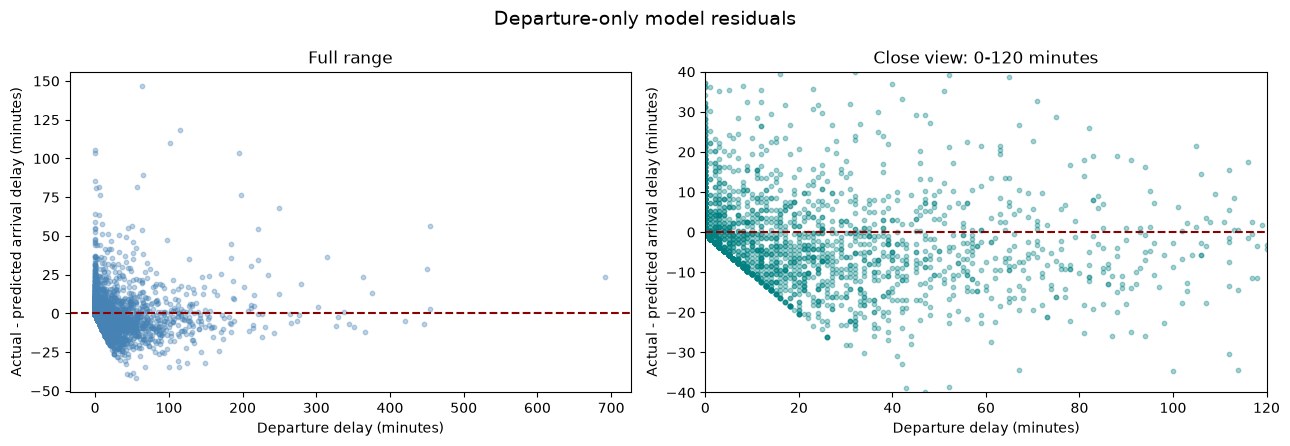

In [49]:
residual_plot_df = pd.DataFrame({
    "Departure delay": X_test["Departure Delay in Minutes"].to_numpy(),
    "Residual": y_test.to_numpy() - departure_predictions
})

# Plot a reproducible sample so overlapping records remain readable.
residual_sample = residual_plot_df.sample(
    n=min(5000, len(residual_plot_df)),
    random_state=1031
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: retain the full range, including extreme delays and errors.
axes[0].scatter(
    residual_sample["Departure delay"],
    residual_sample["Residual"],
    s=10, alpha=0.35, color="steelblue"
)
axes[0].axhline(0, color="darkred", linestyle="--")
axes[0].set_title("Full range")
axes[0].set_xlabel("Departure delay (minutes)")
axes[0].set_ylabel("Actual - predicted arrival delay (minutes)")

# Right: zoom in on common departure delays and moderate errors.
# no records were removed
axes[1].scatter(
    residual_sample["Departure delay"],
    residual_sample["Residual"],
    s=10, alpha=0.35, color="teal"
)
axes[1].axhline(0, color="darkred", linestyle="--")
axes[1].set_xlim(0, 120)
axes[1].set_ylim(-40, 40)
axes[1].set_title("Close view: 0-120 minutes")
axes[1].set_xlabel("Departure delay (minutes)")
axes[1].set_ylabel("Actual - predicted arrival delay (minutes)")

fig.suptitle("Departure-only model residuals", fontsize=14)
plt.tight_layout()

# Export
plt.savefig("visual_9_arrival_delay_residuals.png",
            dpi=300, bbox_inches="tight")
plt.show()

## Visual 10 - Compare the delay-group odds ratios across satisfaction models. 
Each value compares a delayed group with the omitted 0-minute group. An odds ratio below 1 indicates lower modeled odds of satisfaction.

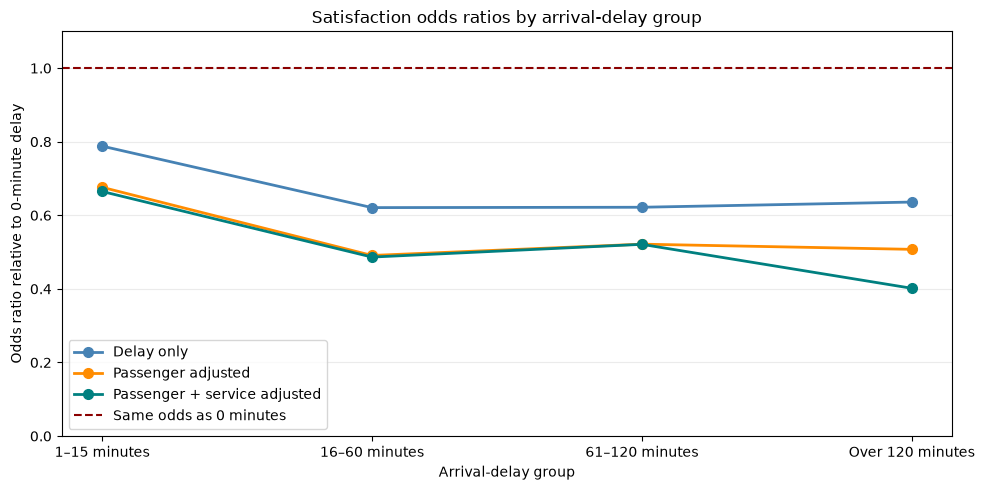

In [50]:
fig, ax = plt.subplots(figsize=(10, 5))

model_lines = [
    ("Delay only", "steelblue"),
    ("Passenger adjusted", "darkorange"),
    ("Passenger + service adjusted", "teal")
]

for model_name, color in model_lines:
    ax.plot(
        all_delay_odds["Delay group"],
        all_delay_odds[model_name],
        marker="o",
        markersize=7,
        linewidth=2,
        color=color,
        label=model_name
    )

# The dashed line represents equal odds to the 0-minute reference group.
ax.axhline(
    1, color="darkred", linestyle="--", linewidth=1.5,
    label="Same odds as 0 minutes"
)

ax.set_title("Satisfaction odds ratios by arrival-delay group")
ax.set_xlabel("Arrival-delay group")
ax.set_ylabel("Odds ratio relative to 0-minute delay")
ax.set_ylim(0, 1.1)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()

# Export 
plt.savefig("visual_10_delay_group_odds_ratios.png",
            dpi=300, bbox_inches="tight")
plt.show()

## Visual 11
Compare how the three satisfaction models distinguish satisfied from neutral/dissatisfied records on the same test set.

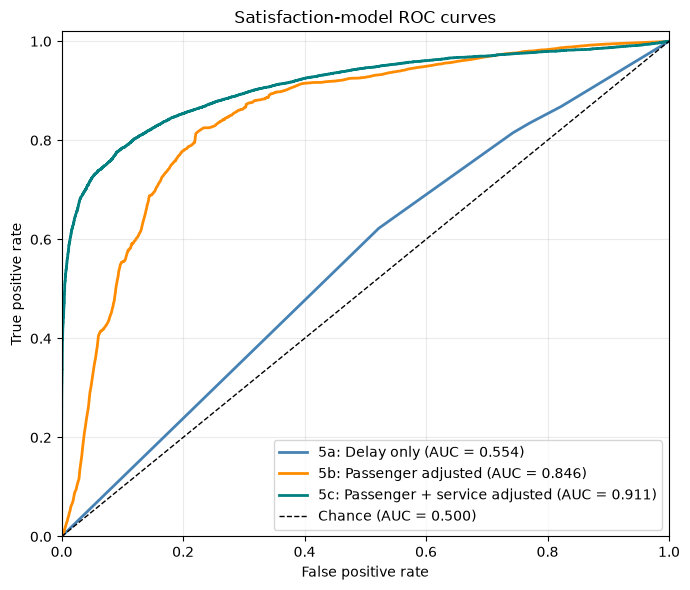

In [51]:
fig, ax = plt.subplots(figsize=(7, 6))

roc_models = [
    ("5a: Delay only", delay_only_probabilities, "steelblue"),
    ("5b: Passenger adjusted", passenger_probabilities, "darkorange"),
    ("5c: Passenger + service adjusted", service_probabilities, "teal")
]

for model_name, probabilities, color in roc_models:
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_sat_test, probabilities
    )
    auc_value = roc_auc_score(y_sat_test, probabilities)

    ax.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        color=color,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

# A model with no ranking ability would follow the diagonal.
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Chance (AUC = 0.500)")

ax.set_title("Satisfaction-model ROC curves")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
plt.tight_layout()

# Export
plt.savefig("visual_11_satisfaction_roc_curves.png",
            dpi=300, bbox_inches="tight")
plt.show()

## Analyze, Part 3 - Micro-Project 4: Model validation and neural networks

This section strengthens the earlier model comparisons with cross-validation
and hyperparameter tuning, then evaluates small feed-forward neural networks
for the two airline questions. Model settings will be selected using training
data and the results will be compared with the existing baselines using the
corresponding held-out test records.

### Model 6a — Cross-validated SVR: departure delay only

I will tune the departure-only SVR using the existing 8,000 training records. The 5,000 test records are not used to choose model settings. Scaling remains inside the model, so each cross-validation fold learns its scaling from that fold's training records.

In [52]:
svr_cv = KFold(n_splits=3, shuffle=True, random_state=1031)

# Trying a small range of settings around the SVR used in Micro-Project 3.
# "regressor__svr__" accesses the SVR inside the target transformer
# and its predictor-scaling pipeline.
svr_parameter_grid = {
    "regressor__svr__C": [1, 10],
    "regressor__svr__epsilon": [0.1, 0.2],
    "regressor__svr__gamma": ["scale", 0.1]
}

svr_departure_search = GridSearchCV(
    estimator=svr_departure,
    param_grid=svr_parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=svr_cv,
    n_jobs=1
)

svr_departure_search.fit(
    X_train_svr[["Departure Delay in Minutes"]],
    y_train_svr
)

print("Best settings:", svr_departure_search.best_params_)
print(
    "Mean cross-validation MAE (minutes):",
    round(-svr_departure_search.best_score_, 3)
)

Best settings: {'regressor__svr__C': 10, 'regressor__svr__epsilon': 0.1, 'regressor__svr__gamma': 0.1}
Mean cross-validation MAE (minutes): 6.455


### Model 6b - Cross-validated SVR: departure delay and flight distance

Tune the two-predictor SVR on the same 8,000 training records. Using the same folds, settings, and MAE measure as Model 6a.

In [53]:
svr_distance_search = GridSearchCV(
    estimator=svr_distance,
    param_grid=svr_parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=svr_cv,
    n_jobs=1
)

svr_distance_search.fit(X_train_svr, y_train_svr)

print("Best settings:", svr_distance_search.best_params_)
print(
    "Mean cross-validation MAE (minutes):",
    round(-svr_distance_search.best_score_, 3)
)

Best settings: {'regressor__svr__C': 10, 'regressor__svr__epsilon': 0.1, 'regressor__svr__gamma': 0.1}
Mean cross-validation MAE (minutes): 6.461


In [54]:
# GridSearchCV refitted each selected SVR on all 8,000 training records.
# Here we will evaluate them on the same 5,000 test records used for the
# sampled linear-regression comparison used earlier in this project.
tuned_svr_departure_predictions = svr_departure_search.best_estimator_.predict(
    X_test_svr[["Departure Delay in Minutes"]]
)
tuned_svr_distance_predictions = svr_distance_search.best_estimator_.predict(
    X_test_svr
)

tuned_svr_comparison = pd.DataFrame([
    regression_scores(
        "Linear: departure only",
        sample_departure_predictions
    ),
    regression_scores(
        "Linear: departure + distance",
        sample_distance_predictions
    ),
    regression_scores(
        "Tuned SVR: departure only",
        tuned_svr_departure_predictions
    ),
    regression_scores(
        "Tuned SVR: departure + distance",
        tuned_svr_distance_predictions
    )
])

display(tuned_svr_comparison.round(3))

,Model,MAE (minutes),RMSE (minutes),R²
0,Linear: departure only,5.385,10.356,0.928
1,Linear: departure + distance,5.381,10.353,0.928
2,Tuned SVR: departure only,6.352,10.318,0.929
3,Tuned SVR: departure + distance,6.290,10.291,0.929


**Tuned SVR finding:** On the shared 5,000-record test sample, the tuned
two-predictor SVR had a slightly lower RMSE and higher R² than the sampled
linear models, but its MAE remained higher (6.290 versus 5.381 minutes for
the two-predictor linear model). Adding flight distance improved the tuned
SVR's test MAE by 0.062 minute, while its cross-validation MAE was slightly
worse than the departure-only SVR's. **The results do not show a consistent,
practically meaningful benefit from flight distance.**

### Model comparison - Cross-validation MAE

Compare the departure-only and departure-plus-distance linear models with the tuned SVR models using the same training sample and three-fold cross-validation. Lower MAE means smaller average prediction errors in minutes.

In [55]:
# Evaluate the sampled linear models on the same cross-validation folds
# used to tune SVR. These scores come only from the 8,000 training records.
linear_departure_cv = -cross_val_score(
    LinearRegression(),
    X_train_svr[["Departure Delay in Minutes"]],
    y_train_svr,
    scoring="neg_mean_absolute_error",
    cv=svr_cv
)

linear_distance_cv = -cross_val_score(
    LinearRegression(),
    X_train_svr,
    y_train_svr,
    scoring="neg_mean_absolute_error",
    cv=svr_cv
)

# Display mean MAE across the three folds. Lower is better.
cv_comparison = pd.DataFrame([
    {
        "Model": "Linear: departure only",
        "Mean CV MAE (minutes)": linear_departure_cv.mean()
    },
    {
        "Model": "Linear: departure + distance",
        "Mean CV MAE (minutes)": linear_distance_cv.mean()
    },
    {
        "Model": "Tuned SVR: departure only",
        "Mean CV MAE (minutes)": -svr_departure_search.best_score_
    },
    {
        "Model": "Tuned SVR: departure + distance",
        "Mean CV MAE (minutes)": -svr_distance_search.best_score_
    }
])

display(cv_comparison.round(3))

,Model,Mean CV MAE (minutes)
0,Linear: departure only,5.321
1,Linear: departure + distance,5.321
2,Tuned SVR: departure only,6.455
3,Tuned SVR: departure + distance,6.461


Across three cross-validation folds, the linear models had the lowest mean absolute error (`5.321` minutes at the displayed precision). Adding flight distance did not meaningfully improve the linear model. The tuned SVR models had higher cross-validation errors, and adding distance did not improve their average performance. These results support the conclusion that **flight distance adds little practical predictive value beyond departure delay in these models.**

### Model 7 — Neural network regression: training and validation data

We will test whether a neural network improves arrival-delay predictions and whether flight distance adds useful information. A validation set will guide training decisions and the existing test set remains separate for final evaluation.

In [56]:
# Split the existing training records into neural-network training
# and validation sets. Keep X_test and y_test separate for final evaluation.
X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=1031
)

print("Neural-network training records:", len(X_nn_train))
print("Validation records:", len(X_nn_val))
print("Held-out test records:", len(X_test))

Neural-network training records: 82871
Validation records: 20718
Held-out test records: 25898


In [57]:
# Fit both scalers on neural-network training records only.
# This keeps information from the validation and test sets out of training.
nn_feature_scaler = StandardScaler()
X_nn_train_scaled = nn_feature_scaler.fit_transform(X_nn_train).astype("float32")
X_nn_val_scaled = nn_feature_scaler.transform(X_nn_val).astype("float32")

# Scale arrival delay during training. We will convert predictions
# back to minutes before comparing models.
nn_target_scaler = StandardScaler()
y_nn_train_scaled = nn_target_scaler.fit_transform(
    y_nn_train.to_numpy().reshape(-1, 1)
).astype("float32")
y_nn_val_scaled = nn_target_scaler.transform(
    y_nn_val.to_numpy().reshape(-1, 1)
).astype("float32")

print("Training predictors:", X_nn_train_scaled.shape)
print("Validation predictors:", X_nn_val_scaled.shape)
print("Training outcome:", y_nn_train_scaled.shape)

Training predictors: (82871, 2)
Validation predictors: (20718, 2)
Training outcome: (82871, 1)


### Model 7a - Neural network: departure delay + flight distance

In [58]:
# Use the fixed seed
tf.keras.utils.set_random_seed(1031)

# Two inputs: departure delay and flight distance.
# The final layer produces one predicted arrival delay (in scaled units).
nn_distance_model = tf.keras.Sequential([
    tf.keras.Input(shape=(2,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1)
])

# MSE guides training, MAE lets us monitor the average error.
# Both are in scaled units until predictions are converted back to minutes.
nn_distance_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

nn_distance_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [59]:
# Stop training when validation loss stops improving.
# Restore the weights from the epoch with the lowest validation loss.
nn_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train on the neural-network training records.
# The validation records are checked after each epoch but are not used
# to update the model's weights.
nn_distance_history = nn_distance_model.fit(
    X_nn_train_scaled,
    y_nn_train_scaled,
    validation_data=(X_nn_val_scaled, y_nn_val_scaled),
    epochs=100,
    batch_size=256,
    callbacks=[nn_early_stopping],
    verbose=1
)

print("Epochs completed:", len(nn_distance_history.history["loss"]))
print("Lowest validation loss:", min(nn_distance_history.history["val_loss"]))

Epoch 1/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 450us/step - loss: 0.2353 - mae: 0.2333 - val_loss: 0.0681 - val_mae: 0.1418
Epoch 2/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step - loss: 0.0675 - mae: 0.1451 - val_loss: 0.0676 - val_mae: 0.1395
Epoch 3/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 306us/step - loss: 0.0672 - mae: 0.1447 - val_loss: 0.0675 - val_mae: 0.1389
Epoch 4/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step - loss: 0.0671 - mae: 0.1445 - val_loss: 0.0674 - val_mae: 0.1388
Epoch 5/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step - loss: 0.0671 - mae: 0.1443 - val_loss: 0.0673 - val_mae: 0.1389
Epoch 6/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 306us/step - loss: 0.0671 - mae: 0.1443 - val_loss: 0.0673 - val_mae: 0.1390
Epoch 7/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 305us/step - loss: 0.0671 - mae: 0.1443 - val_loss: 0.0673 - val_mae: 0.1392
Epoch 8/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 306us/step - loss: 0.0671 - mae: 0.1443 - val_loss: 0.0673 - val_mae: 0.1394
Epoch 9/100
324/324 ━━━━━━━━━━━━

### Visual 12 - Neural network training and validation loss

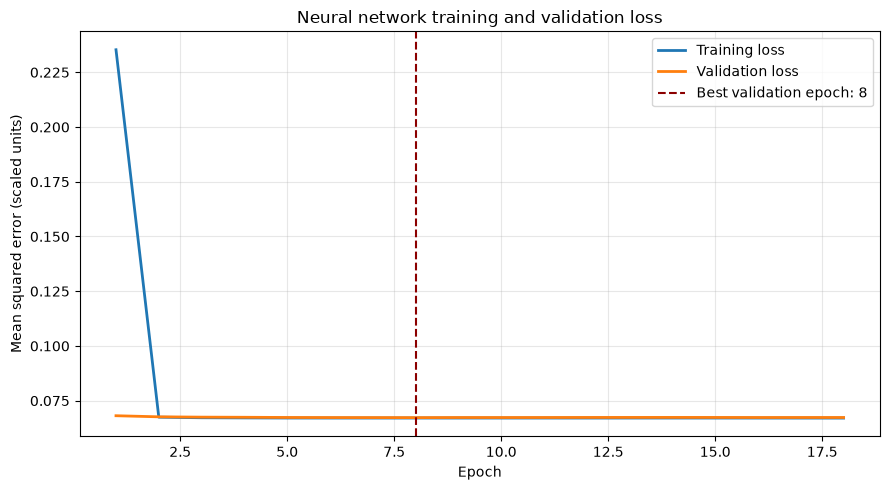

Best validation epoch: 8
Training stopped after epoch: 18


In [60]:
# The model's best weights were restored by EarlyStopping.
# This plot shows when that best validation result occurred.
training_loss = nn_distance_history.history["loss"]
validation_loss = nn_distance_history.history["val_loss"]
epochs = range(1, len(training_loss) + 1)
best_epoch = int(np.argmin(validation_loss)) + 1

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(epochs, training_loss, label="Training loss", linewidth=2)
ax.plot(epochs, validation_loss, label="Validation loss", linewidth=2)
ax.axvline(
    best_epoch,
    color="darkred",
    linestyle="--",
    label=f"Best validation epoch: {best_epoch}"
)

ax.set(
    title="Neural network training and validation loss",
    xlabel="Epoch",
    ylabel="Mean squared error (scaled units)"
)
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("visual_12_nn_training_loss.png", dpi=300, bbox_inches="tight")
plt.show()

print("Best validation epoch:", best_epoch)
print("Training stopped after epoch:", len(training_loss))

**Interpretation:** The neural network's training loss fell sharply during the first two epochs, then changed very little. Validation loss reached its lowest value at `epoch 8`. Training continued to epoch 18 because early stopping allowed 10 additional epochs for possible improvement. Since validation loss did not improve, the model restored its epoch 8 weights. This suggests that further training was unlikely to help on the validation records. These loss values are based on scaled arrival delays, so they do not yet tell us how many minutes the model's predictions are off.

### Model 7a - Held-out test performance

In [61]:
# Apply the feature scaler fitted on neural-network training records.
X_nn_test_scaled = nn_feature_scaler.transform(X_test).astype("float32")

# Predict scaled arrival delays, then convert them back to minutes.
nn_predictions_scaled = nn_distance_model.predict(
    X_nn_test_scaled,
    verbose=0
)
nn_distance_predictions = nn_target_scaler.inverse_transform(
    nn_predictions_scaled
).ravel()

# Compare predictions with the actual arrival delays in minutes.
nn_distance_results = {
    "Model": "Neural network: departure + distance",
    "MAE (minutes)": mean_absolute_error(y_test, nn_distance_predictions),
    "RMSE (minutes)": np.sqrt(
        mean_squared_error(y_test, nn_distance_predictions)
    ),
    "R²": r2_score(y_test, nn_distance_predictions)
}

display(pd.DataFrame([nn_distance_results]).round(3))

,Model,MAE (minutes),RMSE (minutes),R²
0,Neural network: departure + distance,5.322,9.842,0.935


### Model 7a - Compare neural network with a matched linear baseline

In [62]:
# Fit linear regression on the exact records used to train the neural network.
matched_linear_model = LinearRegression()
matched_linear_model.fit(X_nn_train, y_nn_train)

# Predict the same held-out test records used for the neural network.
matched_linear_predictions = matched_linear_model.predict(X_test)

matched_linear_results = {
    "Model": "Linear: departure + distance (matched training set)",
    "MAE (minutes)": mean_absolute_error(y_test, matched_linear_predictions),
    "RMSE (minutes)": np.sqrt(
        mean_squared_error(y_test, matched_linear_predictions)
    ),
    "R²": r2_score(y_test, matched_linear_predictions)
}

display(
    pd.DataFrame([matched_linear_results, nn_distance_results]).round(3)
)

,Model,MAE (minutes),RMSE (minutes),R²
0,Linear: departure + distance (matched training...,5.280,10.023,0.933
1,Neural network: departure + distance,5.322,9.842,0.935


**Interpretation:** When trained on the same records and evaluated on the same held-out flights, the linear model had slightly lower MAE, while the neural network had slightly lower RMSE and higher R². These small, mixed differences do not show a clear practical advantage for the more complex neural network.

### Model 7b - Neural network: departure delay only

In [63]:
# Keep only departure delay for the second neural network.
departure_column = ["Departure Delay in Minutes"]

# Fit a new feature scaler on the same neural-network training records.
nn_departure_scaler = StandardScaler()

X_nn_departure_train_scaled = nn_departure_scaler.fit_transform(
    X_nn_train[departure_column]
).astype("float32")

X_nn_departure_val_scaled = nn_departure_scaler.transform(
    X_nn_val[departure_column]
).astype("float32")

print("Training predictors:", X_nn_departure_train_scaled.shape)
print("Validation predictors:", X_nn_departure_val_scaled.shape)

Training predictors: (82871, 1)
Validation predictors: (20718, 1)


In [64]:
# same random seed used for Model 7a.
tf.keras.utils.set_random_seed(1031)

nn_departure_model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1)
])

nn_departure_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

nn_departure_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 609 (2.38 KB)

 Trainable params: 609 (2.38 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:
# Use a separate early-stopping callback for this model.
nn_departure_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

nn_departure_history = nn_departure_model.fit(
    X_nn_departure_train_scaled,
    y_nn_train_scaled,
    validation_data=(X_nn_departure_val_scaled, y_nn_val_scaled),
    epochs=100,
    batch_size=256,
    callbacks=[nn_departure_early_stopping],
    verbose=1
)

best_departure_epoch = int(
    np.argmin(nn_departure_history.history["val_loss"])
) + 1

print("Best validation epoch:", best_departure_epoch)
print("Epochs completed:", len(nn_departure_history.history["loss"]))
print(
    "Lowest validation loss:",
    min(nn_departure_history.history["val_loss"])
)

Epoch 1/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 453us/step - loss: 0.2389 - mae: 0.2287 - val_loss: 0.0685 - val_mae: 0.1471
Epoch 2/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 312us/step - loss: 0.0676 - mae: 0.1458 - val_loss: 0.0678 - val_mae: 0.1432
Epoch 3/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 311us/step - loss: 0.0674 - mae: 0.1450 - val_loss: 0.0677 - val_mae: 0.1425
Epoch 4/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 310us/step - loss: 0.0673 - mae: 0.1448 - val_loss: 0.0676 - val_mae: 0.1429
Epoch 5/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 311us/step - loss: 0.0673 - mae: 0.1446 - val_loss: 0.0675 - val_mae: 0.1408
Epoch 6/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 310us/step - loss: 0.0673 - mae: 0.1446 - val_loss: 0.0676 - val_mae: 0.1408
Epoch 7/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 310us/step - loss: 0.0673 - mae: 0.1446 - val_loss: 0.0676 - val_mae: 0.1408
Epoch 8/100
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 310us/step - loss: 0.0673 - mae: 0.1446 - val_loss: 0.0676 - val_mae: 0.1411
Epoch 9/100
324/324 ━━━━━━━━━━━━

### Visual 13 - Departure-only neural network training and validation loss

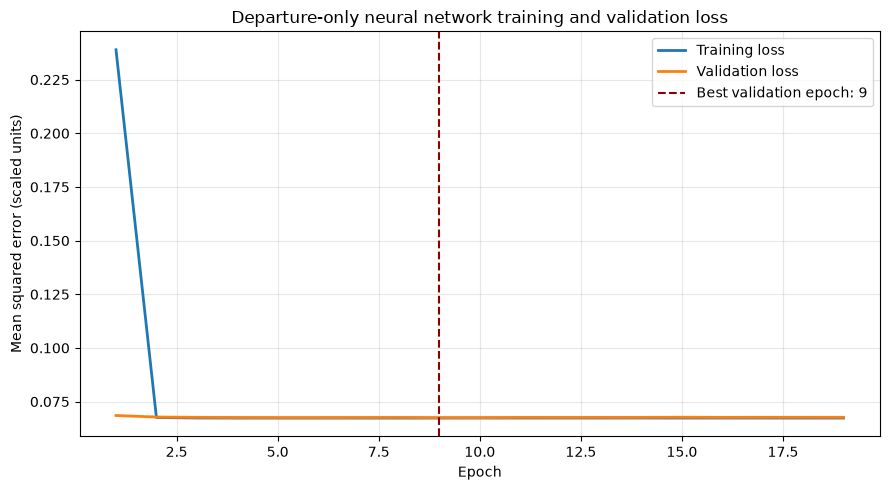

Best validation epoch: 9
Training stopped after epoch: 19


In [66]:
departure_training_loss = nn_departure_history.history["loss"]
departure_validation_loss = nn_departure_history.history["val_loss"]
departure_epochs = range(1, len(departure_training_loss) + 1)
best_departure_epoch = int(np.argmin(departure_validation_loss)) + 1

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(departure_epochs, departure_training_loss,
        label="Training loss", linewidth=2)
ax.plot(departure_epochs, departure_validation_loss,
        label="Validation loss", linewidth=2)
ax.axvline(
    best_departure_epoch,
    color="darkred",
    linestyle="--",
    label=f"Best validation epoch: {best_departure_epoch}"
)

ax.set(
    title="Departure-only neural network training and validation loss",
    xlabel="Epoch",
    ylabel="Mean squared error (scaled units)"
)
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("visual_13_nn_departure_training_loss.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Best validation epoch:", best_departure_epoch)
print("Training stopped after epoch:", len(departure_training_loss))

### Model 7b - Held-out test performance

In [67]:
# Scale the departure-delay column in the held-out test records.
X_nn_departure_test_scaled = nn_departure_scaler.transform(
    X_test[departure_column]
).astype("float32")

# Predict and convert arrival delays back to minutes.
nn_departure_predictions_scaled = nn_departure_model.predict(
    X_nn_departure_test_scaled,
    verbose=0
)
nn_departure_predictions = nn_target_scaler.inverse_transform(
    nn_departure_predictions_scaled
).ravel()

nn_departure_results = {
    "Model": "Neural network: departure only",
    "MAE (minutes)": mean_absolute_error(y_test, nn_departure_predictions),
    "RMSE (minutes)": np.sqrt(
        mean_squared_error(y_test, nn_departure_predictions)
    ),
    "R²": r2_score(y_test, nn_departure_predictions)
}

display(
    pd.DataFrame([nn_departure_results, nn_distance_results]).round(3)
)

,Model,MAE (minutes),RMSE (minutes),R²
0,Neural network: departure only,5.445,9.848,0.935
1,Neural network: departure + distance,5.322,9.842,0.935


**Interpretation:** On the same held-out test flights, the neural network using departure delay and flight distance had a lower MAE than the departure-only network `(5.322 versus 5.445 minutes)`. RMSE was nearly identical, and both models had an `R² of 0.935` when rounded. Flight distance provided a small improvement for this neural network, but the result does not establish a substantial practical gain. The matched linear model still had the lowest `MAE at 5.280 minutes`.

### Compare linear and neural-network models on the same test flights

In [68]:
# Train a departure-only linear model on the same records as both networks.
matched_linear_departure = LinearRegression()
matched_linear_departure.fit(
    X_nn_train[departure_column],
    y_nn_train
)

matched_linear_departure_predictions = matched_linear_departure.predict(
    X_test[departure_column]
)

matched_linear_departure_results = {
    "Model": "Linear: departure only (matched training set)",
    "MAE (minutes)": mean_absolute_error(
        y_test, matched_linear_departure_predictions
    ),
    "RMSE (minutes)": np.sqrt(
        mean_squared_error(y_test, matched_linear_departure_predictions)
    ),
    "R²": r2_score(y_test, matched_linear_departure_predictions)
}

# All four models use the same training records and held-out test flights.
matched_model_comparison = pd.DataFrame([
    matched_linear_departure_results,
    matched_linear_results,
    nn_departure_results,
    nn_distance_results
])

display(matched_model_comparison.round(3))

,Model,MAE (minutes),RMSE (minutes),R²
0,Linear: departure only (matched training set),5.280,10.024,0.933
1,Linear: departure + distance (matched training...,5.280,10.023,0.933
2,Neural network: departure only,5.445,9.848,0.935
3,Neural network: departure + distance,5.322,9.842,0.935


**Overall interpretation:** All four models were trained on the same records and evaluated on the same held-out test flights. Adding flight distance did not change linear regression's MAE when rounded to three decimals `(5.280 minutes for both models)`. It lowered the neural network's `MAE from 5.445 to 5.322 minutes`, but changed RMSE very little. The linear models had the lowest MAE, while the neural networks had slightly lower RMSE. **These results show a small benefit from distance for this neural-network run, without a clear practical advantage over the simpler linear approach.**

### Model 8 - Satisfaction neural network: training and validation split

In [69]:
# Split the existing satisfaction training records.
# Stratification keeps the satisfied/not-satisfied proportions similar.
X_sat_nn_train, X_sat_nn_val, y_sat_nn_train, y_sat_nn_val = train_test_split(
    X_sat_train,
    y_sat_train,
    test_size=0.20,
    random_state=1031,
    stratify=y_sat_train
)

print("Neural-network training records:", len(X_sat_nn_train))
print("Validation records:", len(X_sat_nn_val))
print("Held-out test records:", len(X_sat_test))
print("Training satisfaction rate:", round(y_sat_nn_train.mean() * 100, 1), "%")
print("Validation satisfaction rate:", round(y_sat_nn_val.mean() * 100, 1), "%")

Neural-network training records: 82871
Validation records: 20718
Held-out test records: 25898
Training satisfaction rate: 43.4 %
Validation satisfaction rate: 43.5 %


### Model 8 — Encode and scale satisfaction predictors

In [70]:
sat_nn_features = [
    "delay_group", "Age", "Type of Travel", "Class", "Customer Type"
]

# Use the same predictor groups as logistic Model 5b.
sat_nn_preprocessor = ColumnTransformer(
    transformers=[
        (
            "delay",
            OneHotEncoder(
                categories=[delay_labels],
                drop="first",
                handle_unknown="ignore"
            ),
            ["delay_group"]
        ),
        (
            "passenger",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            ["Type of Travel", "Class", "Customer Type"]
        ),
        (
            "age",
            StandardScaler(),
            ["Age"]
        )
    ],
    sparse_threshold=0  # Return a dense array for TensorFlow.
)

# Learn encoding and scaling from training records only.
X_sat_nn_train_ready = sat_nn_preprocessor.fit_transform(
    X_sat_nn_train[sat_nn_features]
).astype("float32")

# Apply those same learned transformations to validation records.
X_sat_nn_val_ready = sat_nn_preprocessor.transform(
    X_sat_nn_val[sat_nn_features]
).astype("float32")

print("Training predictors:", X_sat_nn_train_ready.shape)
print("Validation predictors:", X_sat_nn_val_ready.shape)

Training predictors: (82871, 9)
Validation predictors: (20718, 9)


### Model 8 - Build the satisfaction neural network

In [71]:
tf.keras.utils.set_random_seed(1031)

sat_nn_model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_sat_nn_train_ready.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

sat_nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.AUC(name="auc")]
)

sat_nn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865 (3.38 KB)

 Trainable params: 865 (3.38 KB)

 Non-trainable params: 0 (0.00 B)

### Train the satisfaction neural network

In [72]:
# Stop when validation loss has not improved for 10 epochs.
# Restore the weights from the epoch with the lowest validation loss.
sat_nn_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train on the training records and check performance on validation records.
# The held-out test set is not used here.
sat_nn_history = sat_nn_model.fit(
    X_sat_nn_train_ready,
    y_sat_nn_train.to_numpy().astype("float32"),
    validation_data=(
        X_sat_nn_val_ready,
        y_sat_nn_val.to_numpy().astype("float32")
    ),
    epochs=200,
    batch_size=256,
    callbacks=[sat_nn_early_stopping],
    verbose=1
)

best_sat_nn_epoch = int(
    np.argmin(sat_nn_history.history["val_loss"]) + 1
)

print("Best validation epoch:", best_sat_nn_epoch)
print("Epochs completed:", len(sat_nn_history.history["loss"]))
print(
    "Lowest validation loss:",
    min(sat_nn_history.history["val_loss"])
)

Epoch 1/200
324/324 ━━━━━━━━━━━━━━━━━━━━ 1s 566us/step - auc: 0.8242 - loss: 0.5207 - val_auc: 0.8513 - val_loss: 0.4745
Epoch 2/200
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 346us/step - auc: 0.8568 - loss: 0.4643 - val_auc: 0.8552 - val_loss: 0.4680
Epoch 3/200
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 343us/step - auc: 0.8590 - loss: 0.4610 - val_auc: 0.8566 - val_loss: 0.4656
Epoch 4/200
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 343us/step - auc: 0.8601 - loss: 0.4595 - val_auc: 0.8574 - val_loss: 0.4642
Epoch 5/200
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 342us/step - auc: 0.8608 - loss: 0.4584 - val_auc: 0.8579 - val_loss: 0.4632
Epoch 6/200
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 344us/step - auc: 0.8613 - loss: 0.4576 - val_auc: 0.8585 - val_loss: 0.4624
Epoch 7/200
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 341us/step - auc: 0.8617 - loss: 0.4569 - val_auc: 0.8588 - val_loss: 0.4618
Epoch 8/200
324/324 ━━━━━━━━━━━━━━━━━━━━ 0s 340us/step - auc: 0.8621 - loss: 0.4563 - val_auc: 0.8593 - val_loss: 0.4612
Epoch 9/200
324/324 ━━━━━━━━━━━━

### Visual 14 - Satisfaction neural network training and validation loss

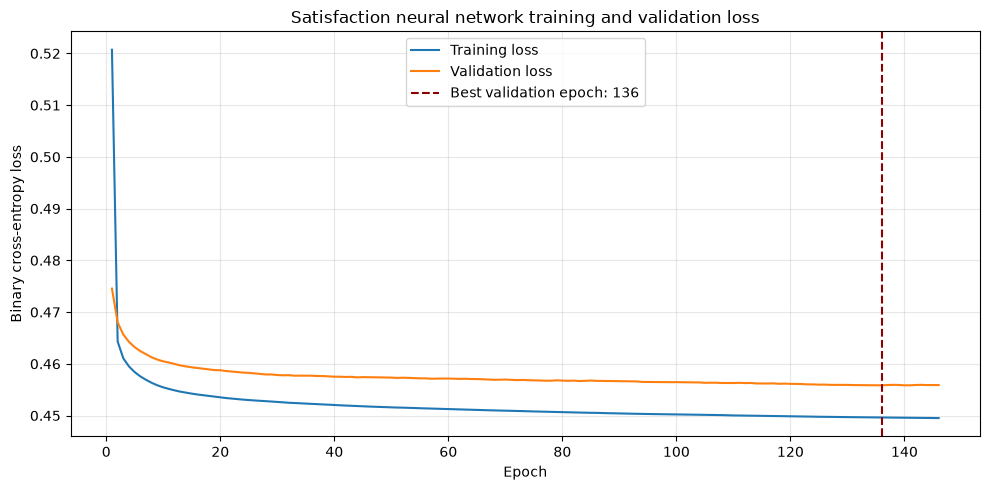

In [73]:
epochs = np.arange(1, len(sat_nn_history.history["loss"]) + 1)
best_epoch = int(np.argmin(sat_nn_history.history["val_loss"]) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs, sat_nn_history.history["loss"], label="Training loss")
plt.plot(epochs, sat_nn_history.history["val_loss"], label="Validation loss")
plt.axvline(
    best_epoch,
    color="darkred",
    linestyle="--",
    label=f"Best validation epoch: {best_epoch}"
)

plt.title("Satisfaction neural network training and validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("visual_14_satisfaction_nn_loss.png", dpi=300, bbox_inches="tight")
plt.show()

### Model 8 - Test-set satisfaction performance

In [74]:
# Use the preprocessor fitted on training records.
X_sat_nn_test_ready = sat_nn_preprocessor.transform(
    X_sat_test[sat_nn_features]
).astype("float32")

# Predict each test passenger's probability of satisfaction.
sat_nn_test_probabilities = sat_nn_model.predict(
    X_sat_nn_test_ready
).ravel()

sat_nn_test_auc = roc_auc_score(
    y_sat_test, sat_nn_test_probabilities
)
sat_nn_test_log_loss = log_loss(
    y_sat_test, sat_nn_test_probabilities
)

print(f"Neural network test ROC AUC: {sat_nn_test_auc:.3f}")
print(f"Neural network test log loss: {sat_nn_test_log_loss:.3f}")

810/810 ━━━━━━━━━━━━━━━━━━━━ 0s 143us/step
Neural network test ROC AUC: 0.867
Neural network test log loss: 0.449


### Matched logistic regression comparison

In [75]:
# Clone the existing passenger-adjusted logistic pipeline so its
# preprocessing and coefficients are fitted on this matched training set.
matched_passenger_model = clone(passenger_sat_model)

matched_passenger_model.fit(
    X_sat_nn_train[sat_nn_features],
    y_sat_nn_train
)

matched_logistic_probabilities = matched_passenger_model.predict_proba(
    X_sat_test[sat_nn_features]
)[:, 1]

matched_comparison = pd.DataFrame({
    "Model": [
        "Logistic regression: passenger adjusted",
        "Neural network: passenger adjusted"
    ],
    "Test ROC AUC": [
        roc_auc_score(y_sat_test, matched_logistic_probabilities),
        sat_nn_test_auc
    ],
    "Test log loss": [
        log_loss(y_sat_test, matched_logistic_probabilities),
        sat_nn_test_log_loss
    ]
})

display(matched_comparison.round(3))

,Model,Test ROC AUC,Test log loss
0,Logistic regression: passenger adjusted,0.846,0.474
1,Neural network: passenger adjusted,0.867,0.449


### Visual 15 - Matched satisfaction-model ROC curves

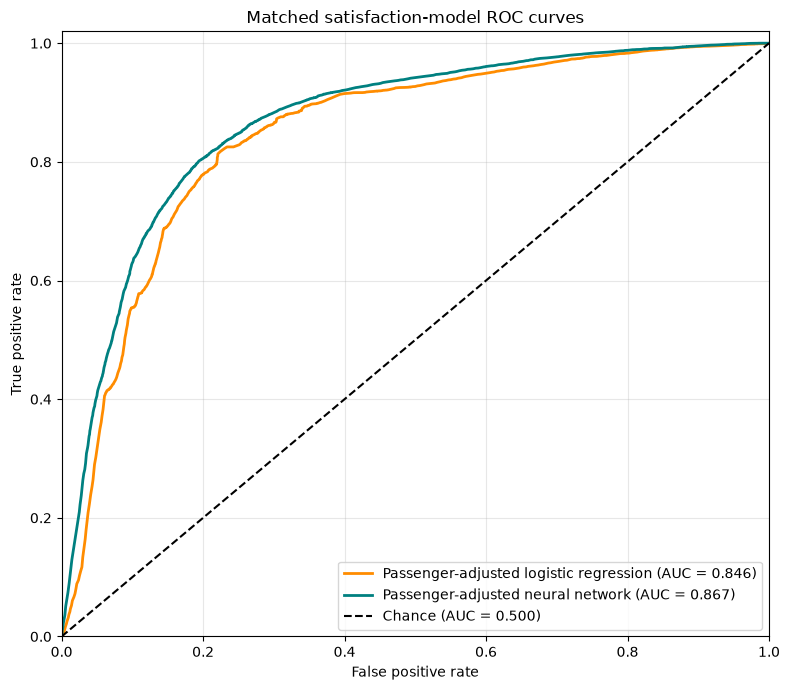

In [76]:
# Both curves use predictions for the same held-out test passengers.
log_fpr, log_tpr, _ = roc_curve(
    y_sat_test, matched_logistic_probabilities
)
nn_fpr, nn_tpr, _ = roc_curve(
    y_sat_test, sat_nn_test_probabilities
)

log_auc = roc_auc_score(y_sat_test, matched_logistic_probabilities)
nn_auc = roc_auc_score(y_sat_test, sat_nn_test_probabilities)

plt.figure(figsize=(8, 7))
plt.plot(
    log_fpr, log_tpr,
    color="darkorange",
    linewidth=2,
    label=f"Passenger-adjusted logistic regression (AUC = {log_auc:.3f})"
)
plt.plot(
    nn_fpr, nn_tpr,
    color="teal",
    linewidth=2,
    label=f"Passenger-adjusted neural network (AUC = {nn_auc:.3f})"
)
plt.plot(
    [0, 1], [0, 1],
    color="black",
    linestyle="--",
    label="Chance (AUC = 0.500)"
)

plt.title("Matched satisfaction-model ROC curves")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(
    "visual_15_matched_satisfaction_roc.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Interpretation**: Using the same five predictors and matched training and test records, the neural network performed better than passenger-adjusted logistic regression. Its test `ROC AUC was 0.867 versus 0.846`, indicating better separation between satisfied and dissatisfied passengers. Its `log loss was also lower (0.449 versus 0.474)`, indicating better predicted probabilities. **This improvement was observed on one held-out test split**. Because arrival-delay information is among the predictors, these models describe satisfaction after the flight, where the results do not establish that delay causes dissatisfaction.

## Step 4 — Report

### Arrival delay (H₁a)

On the full held-out test set in Micro-Project 3, the departure-delay-only linear model had an `MAE of 5.289` minutes and an `R² of 0.933`. Adding flight distance reduced `MAE by only about 0.0005 minutes`, and adding a departure-delay-by-distance interaction did not improve test performance. In the separate 8,000-record training sample used for SVR, neither tested SVR model outperformed the corresponding linear models.

Micro-Project 4 strengthened this comparison with cross-validation and hyperparameter tuning. On the cross-validation sample, both linear models had a mean `MAE of 5.321 minutes`. The tuned SVR models had higher mean MAEs: `6.455 minutes` with departure delay alone and `6.461 minutes` with departure delay and distance.

The neural networks and matched linear models were also evaluated on the held-out test records. Both matched linear models had an `MAE of 5.280 minutes`. Adding distance to the neural network reduced its `MAE from 5.445 to 5.322 minutes`, an improvement of `0.123 minutes (about 7 seconds)`, while its `RMSE changed only from 9.848 to 9.842 minutes`. The linear models had the lowest MAE, while the neural networks had slightly lower RMSE. Across these tests, flight distance provided limited practical benefit after departure delay was included.

### Passenger satisfaction (H₁b)

The percentage satisfied fell from **47.4%** among records with no arrival delay to **35.9%** among records with a 16-60 minute delay, then stayed near **35-36%** across longer delay groups rather than continuing to decline as delays grew longer. Logistic models showed lower odds of satisfaction for every delayed group compared with zero delay, including after accounting for passenger, travel, and selected service characteristics. Delay group alone had limited predictive ability `(test ROC AUC = 0.554)`. Adding it to the passenger and service model `raised test ROC AUC from 0.9079 to 0.9106` and `lowered log loss from 0.3808 to 0.3746`.

In Micro-Project 4, a neural network was compared with passenger-adjusted logistic regression using the same five predictors, matched training records, and the same held-out test records. The neural network achieved a test `ROC AUC of 0.867`, compared with `0.846` for logistic regression. It also had `lower log loss (0.449 versus 0.474)`. The matched ROC curves show the neural network performing better across most classification thresholds. This improvement was observed on one test split.

These findings describe associations in the provided dataset and do not establish that arrival delay causes dissatisfaction. Models that include arrival-delay group require the delay to be known. The service ratings were collected alongside satisfaction, so the higher scores from models using those ratings should not be presented as preflight prediction performance.

## Step 5: Act

The model comparisons support a simple starting point for arrival-delay planning and a targeted approach to studying passenger satisfaction.

### Arrival-delay planning

Use departure delay as the starting point for estimating arrival delay. The departure-only linear model achieved a test `MAE of 5.289 minutes` and `R² of 0.933` in Micro-Project 3. Adding flight distance or a departure-delay-by-distance interaction produced little practical improvement. Micro-Project 4 cross-validation reinforced this finding. Both linear models had a mean `MAE of 5.321 minutes`, while the tuned SVR models had higher mean `MAEs of 6.455 and 6.461 minutes`.

In the matched held-out comparison, the linear models had lower MAE than the neural networks. Although adding distance improved the neural network's `MAE by about 0.123 minutes (roughly 7 seconds)`, it did not change the planning recommendation. Before using arrival-delay estimates operationally, examine the large errors for unusually long delays and assess performance on new flight records.

### Passenger satisfaction

Satisfaction fell sharply between the no-delay group and the delayed groups. The adjusted models continued to show an association between delay and lower satisfaction, but delay group alone was a weak satisfaction classifier `(test ROC AUC = 0.554)`.

Passenger characteristics improved classification. In the matched comparison using passenger and delay predictors, the neural network performed better than logistic regression (test `ROC AUC 0.867 versus 0.846`, and `log loss 0.449 versus 0.474`). These models could help describe which passengers reported dissatisfaction after their flights, but they require the arrival delay to be known. The stronger model that includes service ratings (`AUC = 0.911`) is useful for retrospective analysis because those ratings were collected alongside satisfaction.

A reasonable action to test is providing timely updates and support when delays occur. Measure whether a specific change improves subsequent passenger experience. The associations in this dataset alone cannot establish that the action will increase satisfaction.

### Follow-up analysis

Examine which individual service ratings are associated with satisfaction within travel types and classes, then test a specific service improvement. For arrival-delay prediction, investigate additional operational variables if they become available, such as route, weather, and scheduled flight duration. Evaluate revised models on new records before recommending them for planning.